In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib import font_manager
from IPython.display import Image, display

DATA = Path("figures_data")
OUT = Path("Figures")
OUT.mkdir(exist_ok=True)
# STIX Two Text is optional; use an installed serif font on a fresh machine.
available_fonts = {entry.name for entry in font_manager.fontManager.ttflist}
SERIF_FONTS = [name for name in ("STIX Two Text", "Times New Roman", "DejaVu Serif")
               if name in available_fonts]

# Also write the filenames referenced by main_arxiv.tex.
PAPER_FILENAMES = {
    1: "Fig1_Legacy_memorization_arithmetic.pdf",
    8: "Fig1_Legacy_time_CNN.pdf",
    9: "Fig5_BCE_extended_parametric_2000_PREVIEW.pdf",
    10: "Fig5_BCE_extended_time_trajectories_2000_PREVIEW.pdf",
    11: "RAF_dynamics_optimizer_robustness.pdf",
    14: "CatDog_square_parametric.pdf",
    15: "CatDog_square_trajectories.pdf",
    16: "CatDog_BCE_parametric_PREVIEW.pdf",
    17: "CatDog_BCE_trajectories_PREVIEW.pdf",
    12: "ResNet_BCE_controls_std.pdf",
    13: "ResNet_square_controls_dense_arithmetic_std_PREVIEW.pdf",
}

def save_paper_alias(fig, n):
    fig.savefig(OUT / PAPER_FILENAMES[n], bbox_inches="tight")

def load(n):
    return pd.read_csv(DATA / f"Figure{n}.csv", float_precision="round_trip")

def save(fig, n):
    fig.savefig(OUT / f"Figure{n}.pdf", bbox_inches="tight")
    save_paper_alias(fig, n)
    fig.savefig(OUT / f"Figure{n}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / f"Figure{n}.png"), width=1200))

def style1():
    plt.rcdefaults()
    plt.rcParams.update({"font.family":"serif", "mathtext.fontset":"cm", "font.size":18,
        "axes.labelsize":26, "axes.titlesize":24, "xtick.labelsize":18, "ytick.labelsize":18,
        "legend.fontsize":21, "pdf.fonttype":42, "ps.fonttype":42,
        "axes.spines.top":False, "axes.spines.right":False})

SQUARE = {"rf_readout":("RF-CNN (readout matched)","#2875B9"),
          "cnn2":("Two-layer CNN","#009B83"), "cnn4":("Four-layer CNN","#D84343"),
          "cnn6":("Six-layer CNN","#C28B18"), "res16":("ResNet-16","#242424"),
          "res28":("WRN-28","#AD4B9C")}
BCE = {"shallow":("Four-layer CNN","#D84343"), "residual":("ResNet-16","#242424"),
       "cnn6":("Six-layer CNN","#C28B18"), "res28":("WRN-28","#AD4B9C"),
       "mobilev2":("MobileNetV2","#2875B9")}


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


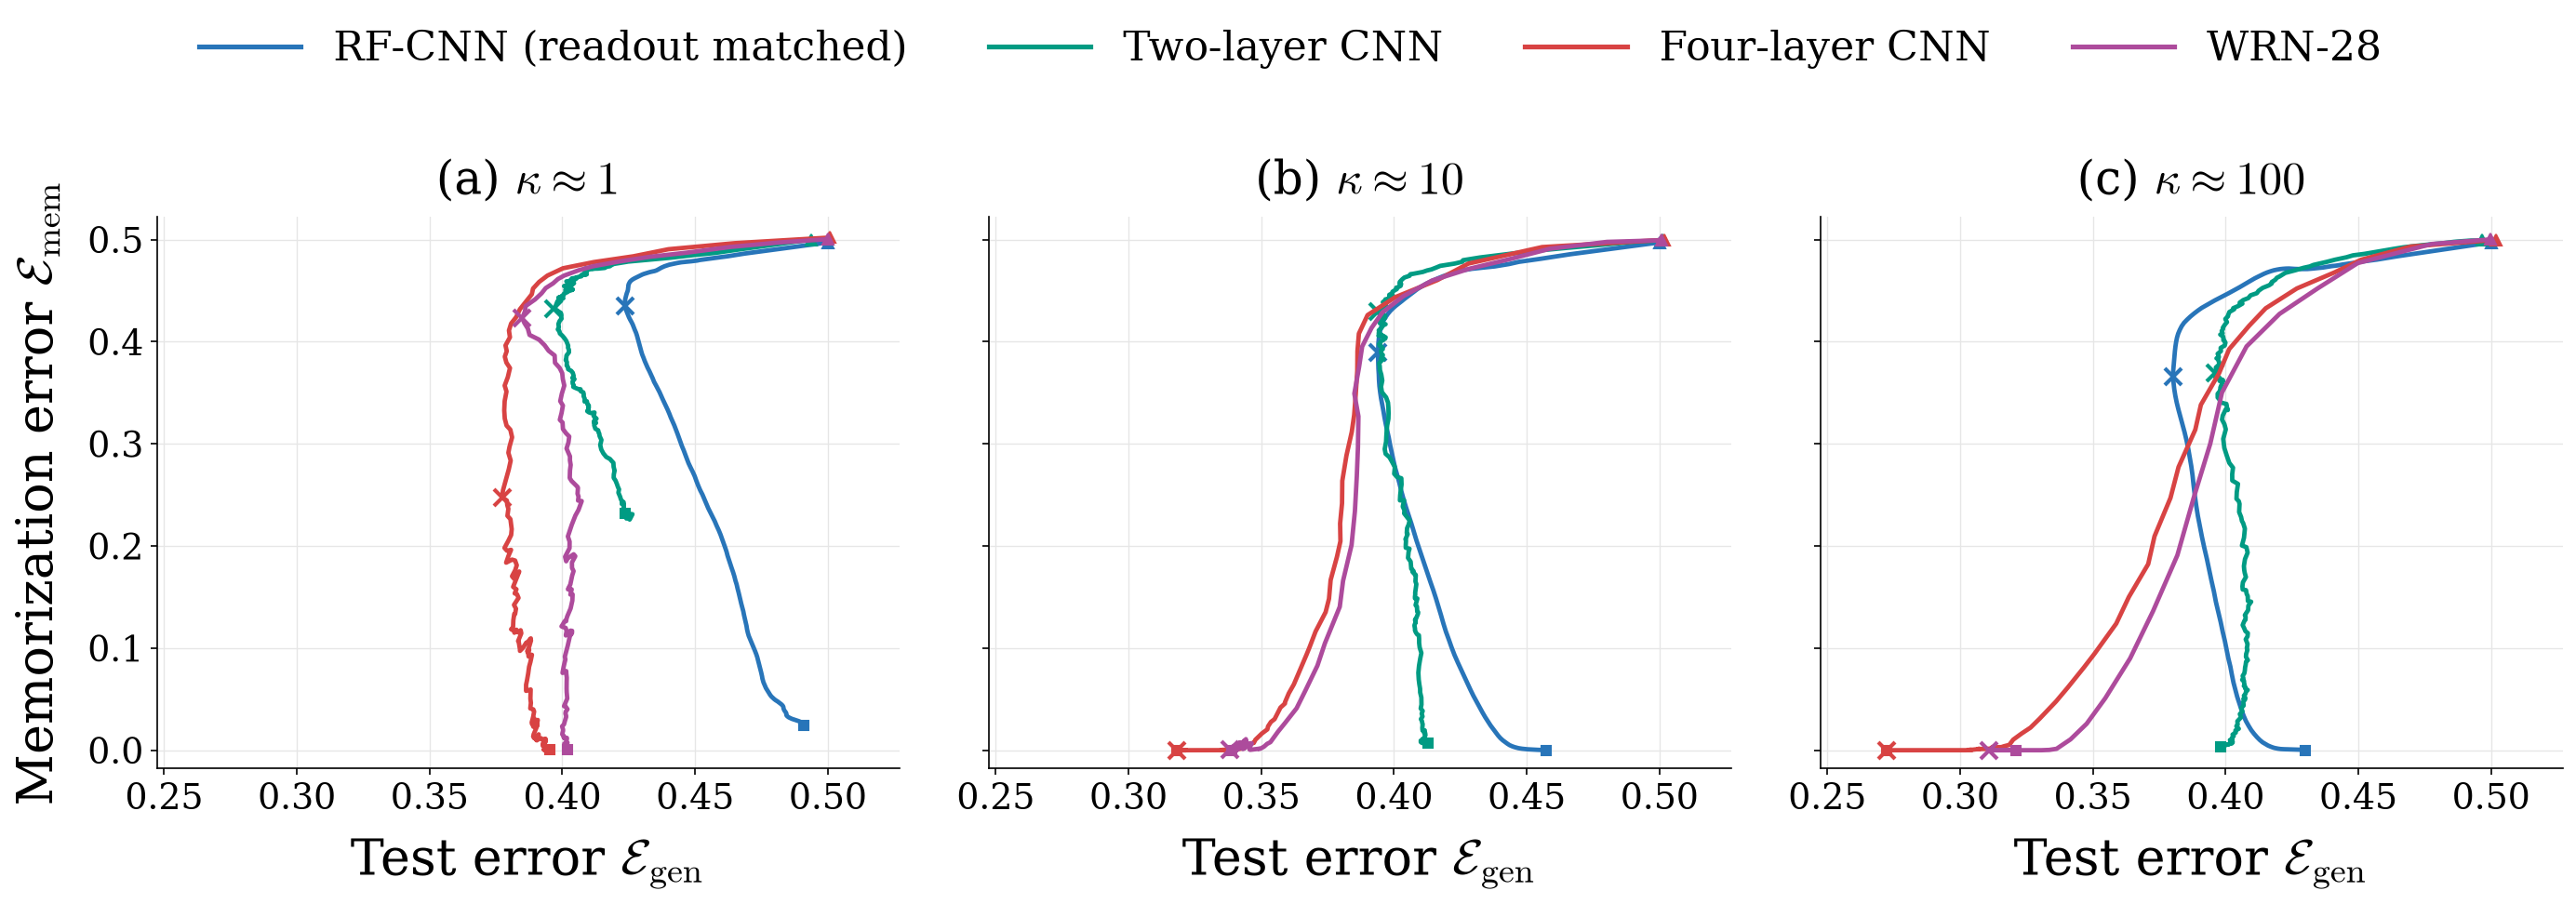

In [2]:
style1()
d = load(1)
architectures = ("rf_readout", "cnn2", "cnn4", "res28")
fig, axes = plt.subplots(1,3,figsize=(18.8,6.7),sharex=True,sharey=True)
for j,(ax,k) in enumerate(zip(axes,(1,10,100))):
    for a in architectures:
        g = d[(d.kappa==k)&(d.architecture==a)].sort_values("time")
        x,y = g.E_gen.to_numpy(),g.E_mem.to_numpy()
        color = SQUARE[a][1]
        ax.plot(x,y,color=color,lw=2.3)
        ax.plot(x[0],y[0],marker="^",ms=6,color=color)
        best = np.argmin(x)
        ax.plot(x[best],y[best],marker="x",ms=9,mew=2,color=color)
        ax.plot(x[-1],y[-1],marker="s",ms=5,color=color)
    ax.set_title(rf"({chr(97+j)}) $\kappa\approx {k}$",pad=12,fontsize=24)
    ax.set_xlim(max(0.,d.E_gen.min()-.025),max(.52,d.E_gen.max()+.025))
    ax.set_ylim(-.018,max(.52,d.E_mem.max()+.02))
    ax.set_yticks(np.arange(0,.51,.1))
    ax.grid(True,color=".9",lw=.65); ax.set_axisbelow(True)
    ax.set_xlabel(r"Test error $\mathcal{E}_{\rm gen}$",labelpad=10)
axes[0].set_ylabel(r"Memorization error $\mathcal{E}_{\rm mem}$",labelpad=12)
fig.legend(handles=[Line2D([],[],color=SQUARE[a][1],lw=2.5,label=SQUARE[a][0]) for a in architectures],
           loc="upper center",bbox_to_anchor=(.5,1.),ncol=4,frameon=False,columnspacing=2.,handlelength=2.5)
fig.subplots_adjust(top=.76,bottom=.17,left=.068,right=.985,wspace=.12)
save(fig,1)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


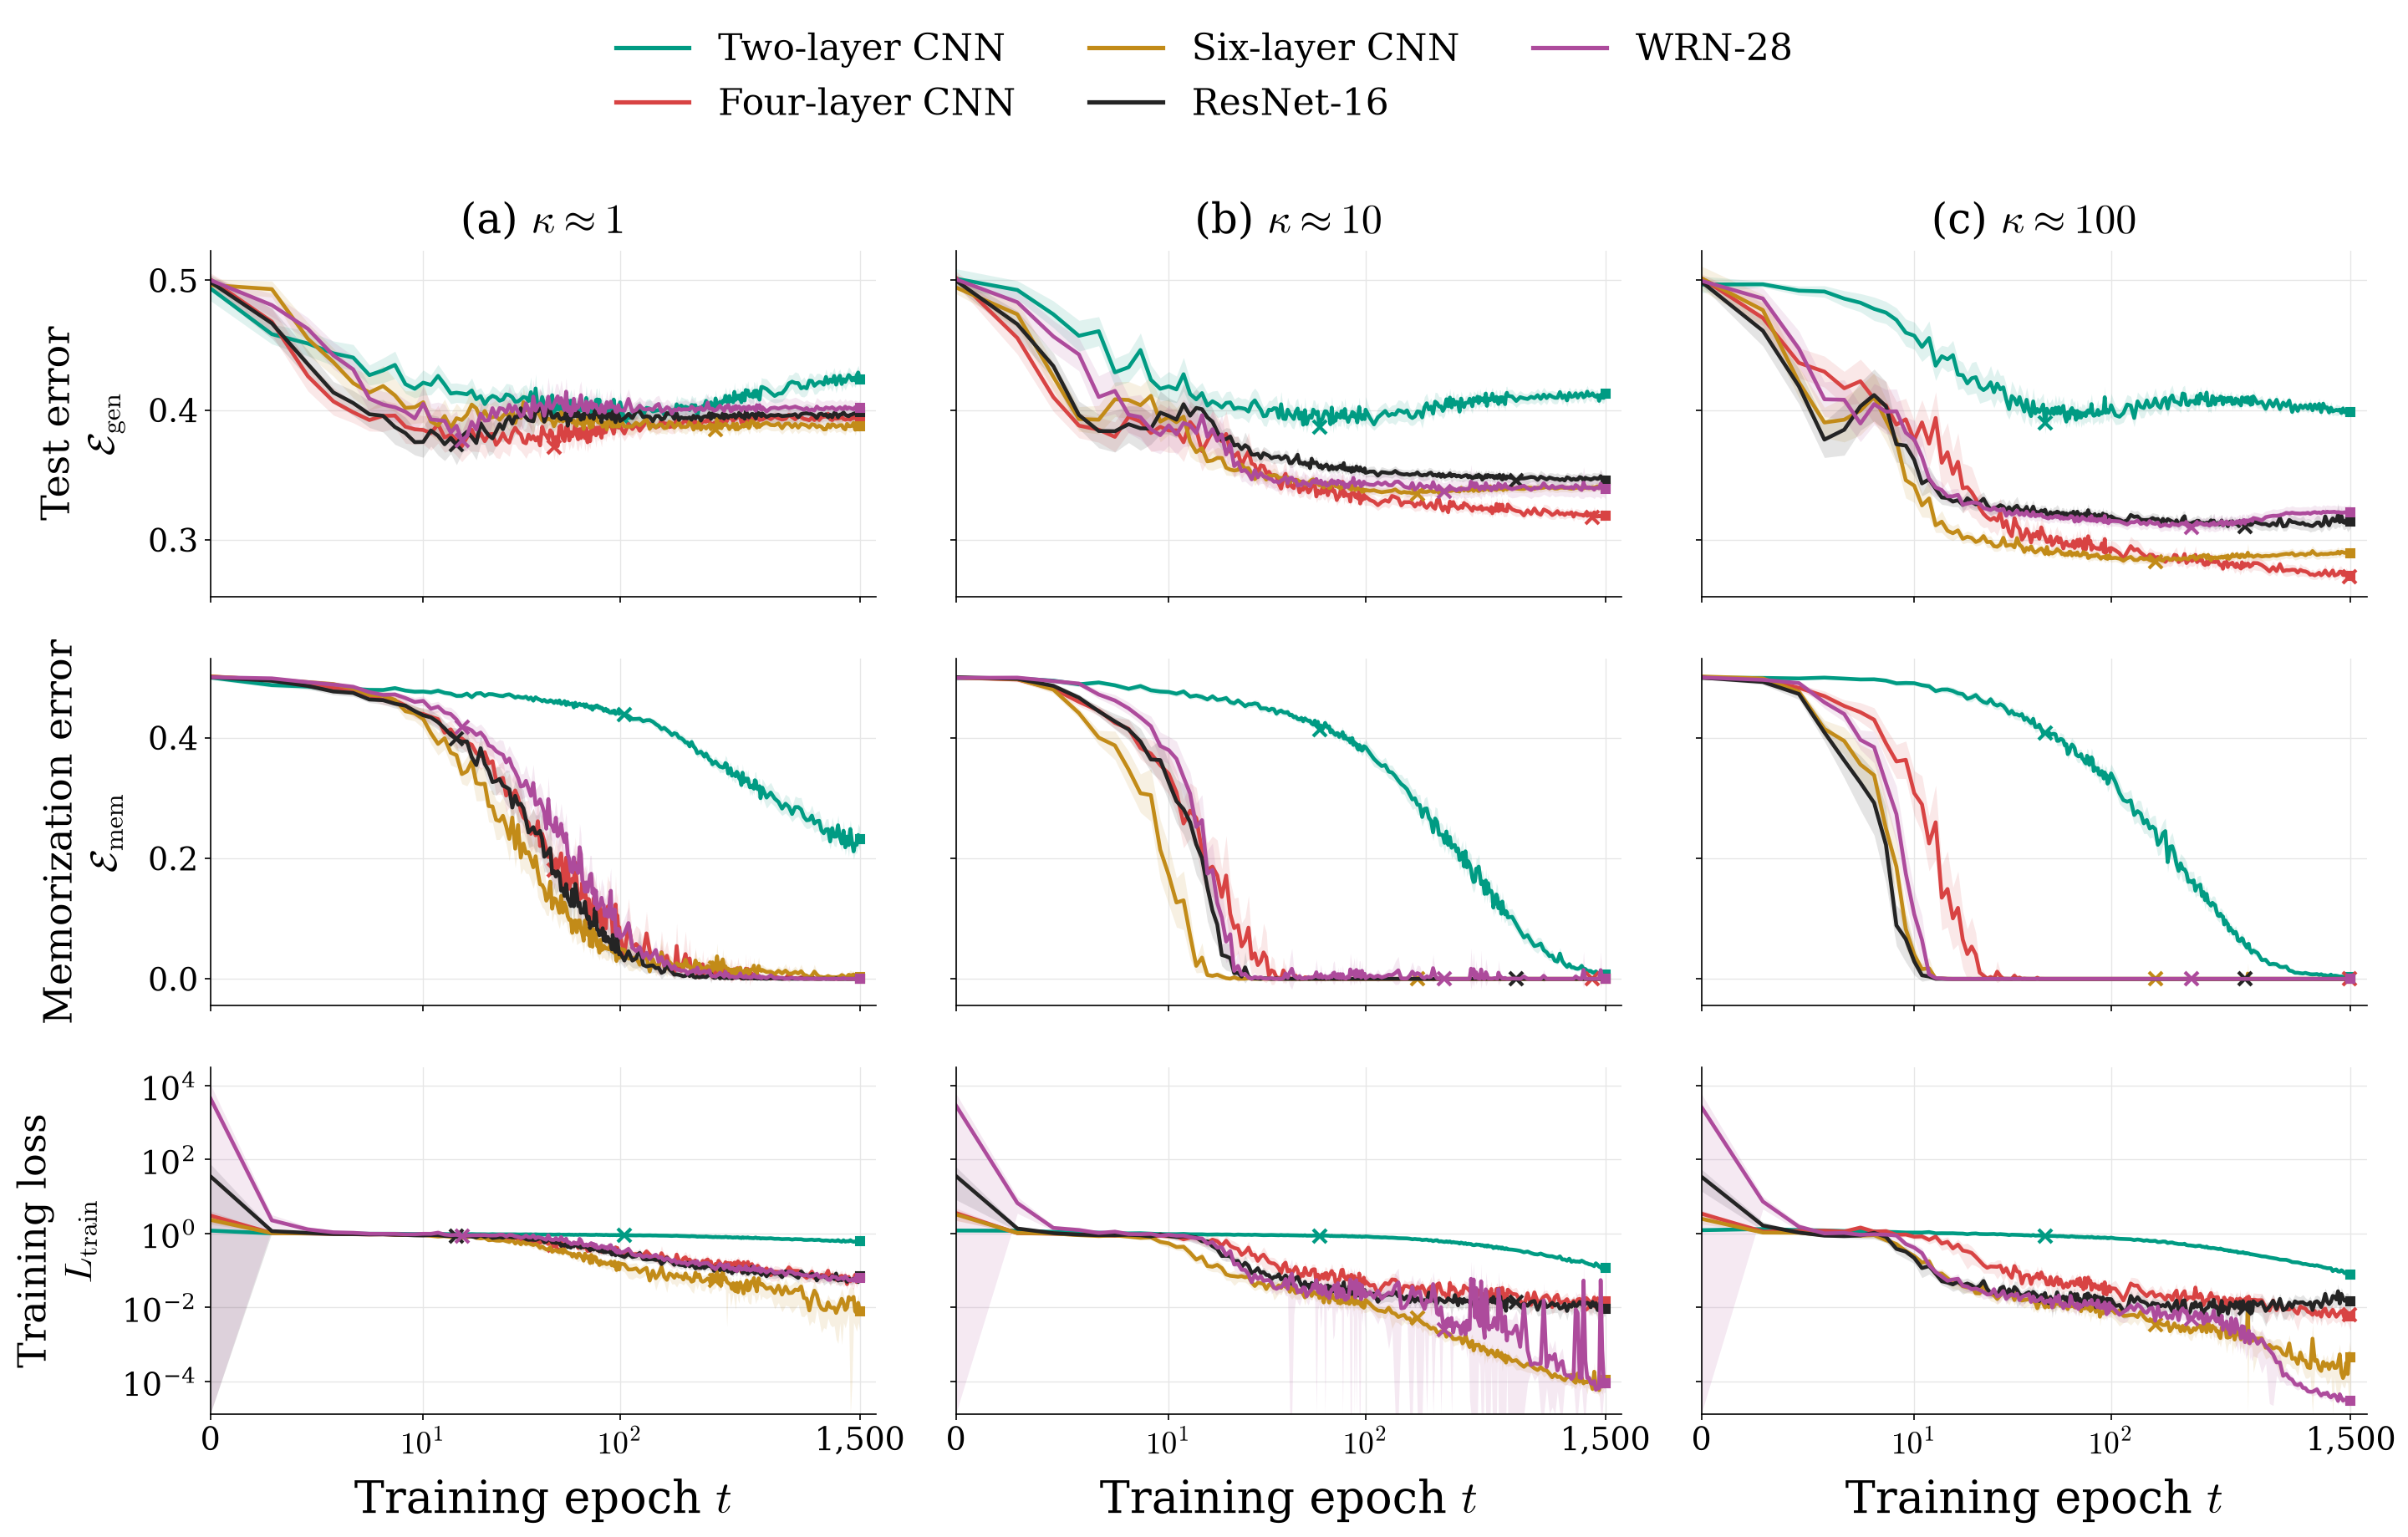

In [3]:
style1()
d = load(8)
architectures = ("cnn2","cnn4","cnn6","res16","res28")
metrics = ("E_gen","E_mem","train_loss")
fig,axes = plt.subplots(3,3,figsize=(18.8,12.8),sharex=True,sharey="row")
for col,k in enumerate((1,10,100)):
    for a in architectures:
        g = d[(d.kappa==k)&(d.architecture==a)].sort_values("time")
        x = np.log10(1+g.time.to_numpy())
        best = np.argmin(g.E_gen.to_numpy())
        color = SQUARE[a][1]
        for row,m in enumerate(metrics):
            ax = axes[row,col]; y = g[m].to_numpy()
            ax.plot(x,y,color=color,lw=2.2)
            ax.fill_between(x,g[m+"_lower"],g[m+"_upper"],color=color,alpha=.12,linewidth=0)
            ax.plot(x[best],y[best],"x",color=color,ms=8,mew=2)
            ax.plot(x[-1],y[-1],"s",color=color,ms=5)
    axes[0,col].set_title(rf"({chr(97+col)}) $\kappa\approx {k}$",pad=10,fontsize=24)
    for ax in axes[:,col]:
        ax.grid(True,color=".9",linewidth=.65); ax.set_axisbelow(True)
        ax.set_xlim(0,np.log10(1+d.time.max())*1.025)
    axes[2,col].set_yscale("log",nonpositive="mask")
    axes[2,col].set_xticks(np.log10(1+np.array([0,10,100,1500])),["0",r"$10^1$",r"$10^2$","1,500"])
    axes[2,col].set_xlabel(r"Training epoch $t$",labelpad=10)
for row,label in enumerate(["Test error\n"+r"$\mathcal{E}_{\rm gen}$",
                            "Memorization error\n"+r"$\mathcal{E}_{\rm mem}$",
                            "Training loss\n"+r"$L_{\rm train}$"]):
    axes[row,0].set_ylabel(label,labelpad=10,fontsize=22)
axes[2,0].set_ylim(bottom=d.loc[d.train_loss>0,"train_loss"].min()*.5)
fig.legend(handles=[Line2D([],[],color=SQUARE[a][1],lw=2.5,label=SQUARE[a][0]) for a in architectures],
           loc="upper center",ncol=3,frameon=False,fontsize=21)
fig.subplots_adjust(top=.84,bottom=.115,left=.07,right=.985,wspace=.12,hspace=.18)
save(fig,8)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


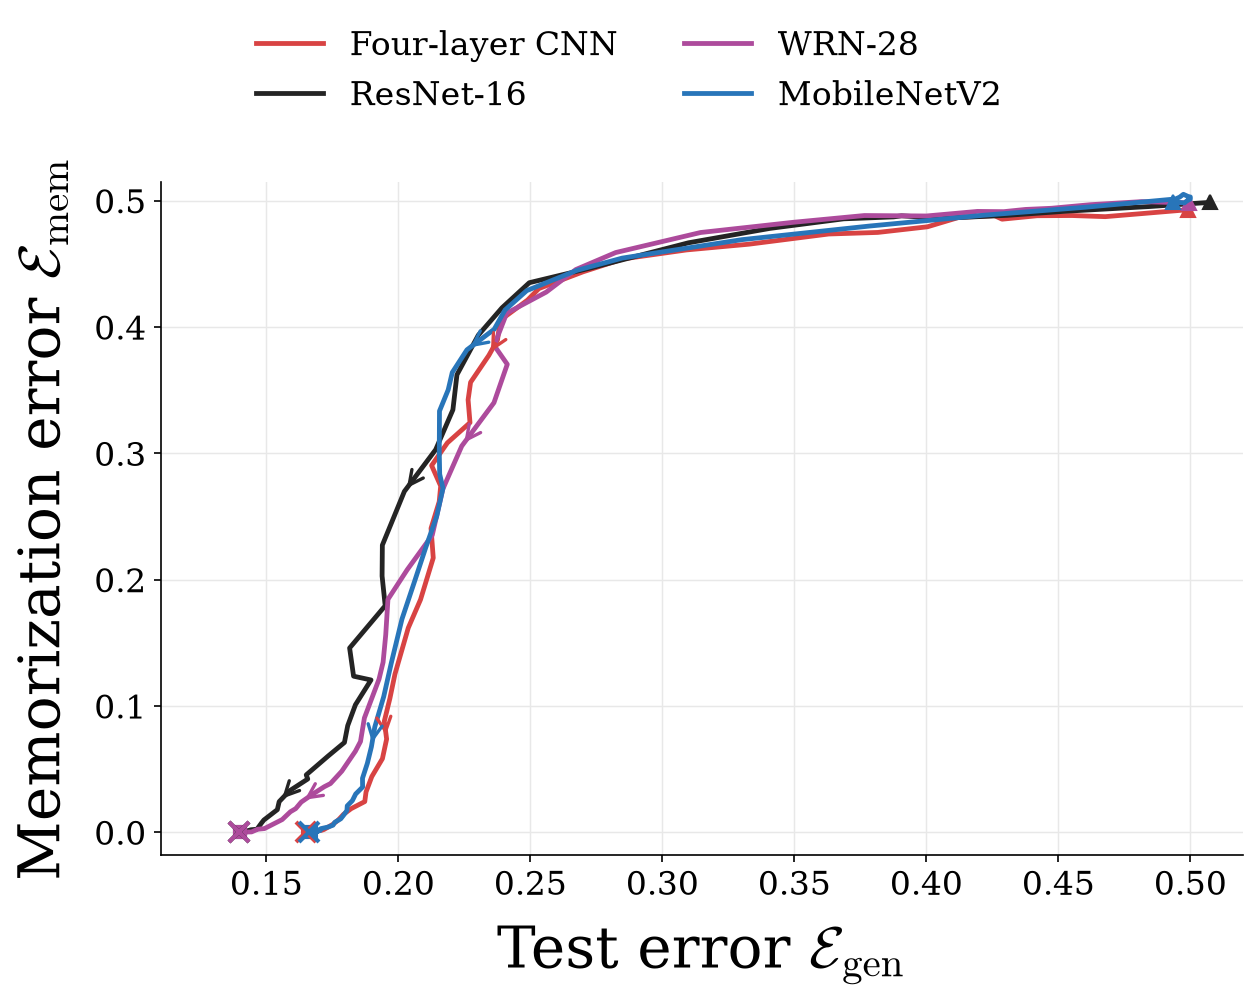

In [4]:
plt.rcdefaults()
plt.rcParams.update({"font.family":"serif", "mathtext.fontset":"cm", "font.size":16,
    "axes.labelsize":28, "xtick.labelsize":16, "ytick.labelsize":16,
    "pdf.fonttype":42, "axes.spines.top":False, "axes.spines.right":False})
d = load(9)
fig,ax = plt.subplots(figsize=(8.8,6.8))
for a in ("shallow","residual","res28","mobilev2"):
    g = d[d.architecture==a].sort_values("time")
    x,y = g.E_gen.to_numpy(),g.E_mem.to_numpy()
    name,color = BCE[a]
    ax.plot(x,y,color=color,lw=2.3,label=name)
    ax.plot(x[0],y[0],"^",color=color,ms=7)
    ax.plot(x[-1],y[-1],"s",color=color,ms=6,zorder=4)
    best = np.argmin(x)
    ax.plot(x[best],y[best],"x",color=color,ms=10,mew=2,zorder=5)
    for target in (50,150):
        i = np.searchsorted(g.time.to_numpy(),target)
        if 0<i<len(x) and (x[i],y[i])!=(x[i-1],y[i-1]):
            ax.annotate("",xy=(x[i],y[i]),xytext=(x[i-1],y[i-1]),
                arrowprops=dict(arrowstyle="->",color=color,lw=1.6,mutation_scale=17))
ax.set_xlabel(r"Test error $\mathcal{E}_{\rm gen}$",labelpad=10)
ax.set_ylabel(r"Memorization error $\mathcal{E}_{\rm mem}$",labelpad=10)
ax.set_xlim(.11,.52); ax.set_ylim(-.018,.515)
ax.set_xticks(np.arange(.15,.51,.05)); ax.set_yticks(np.arange(0,.51,.1))
ax.grid(True,color=".91",lw=.7); ax.set_axisbelow(True)
fig.legend(*ax.get_legend_handles_labels(),loc="upper center",ncol=2,frameon=False,fontsize=16)
fig.subplots_adjust(top=.82,bottom=.16,left=.16,right=.98)
save(fig,9)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


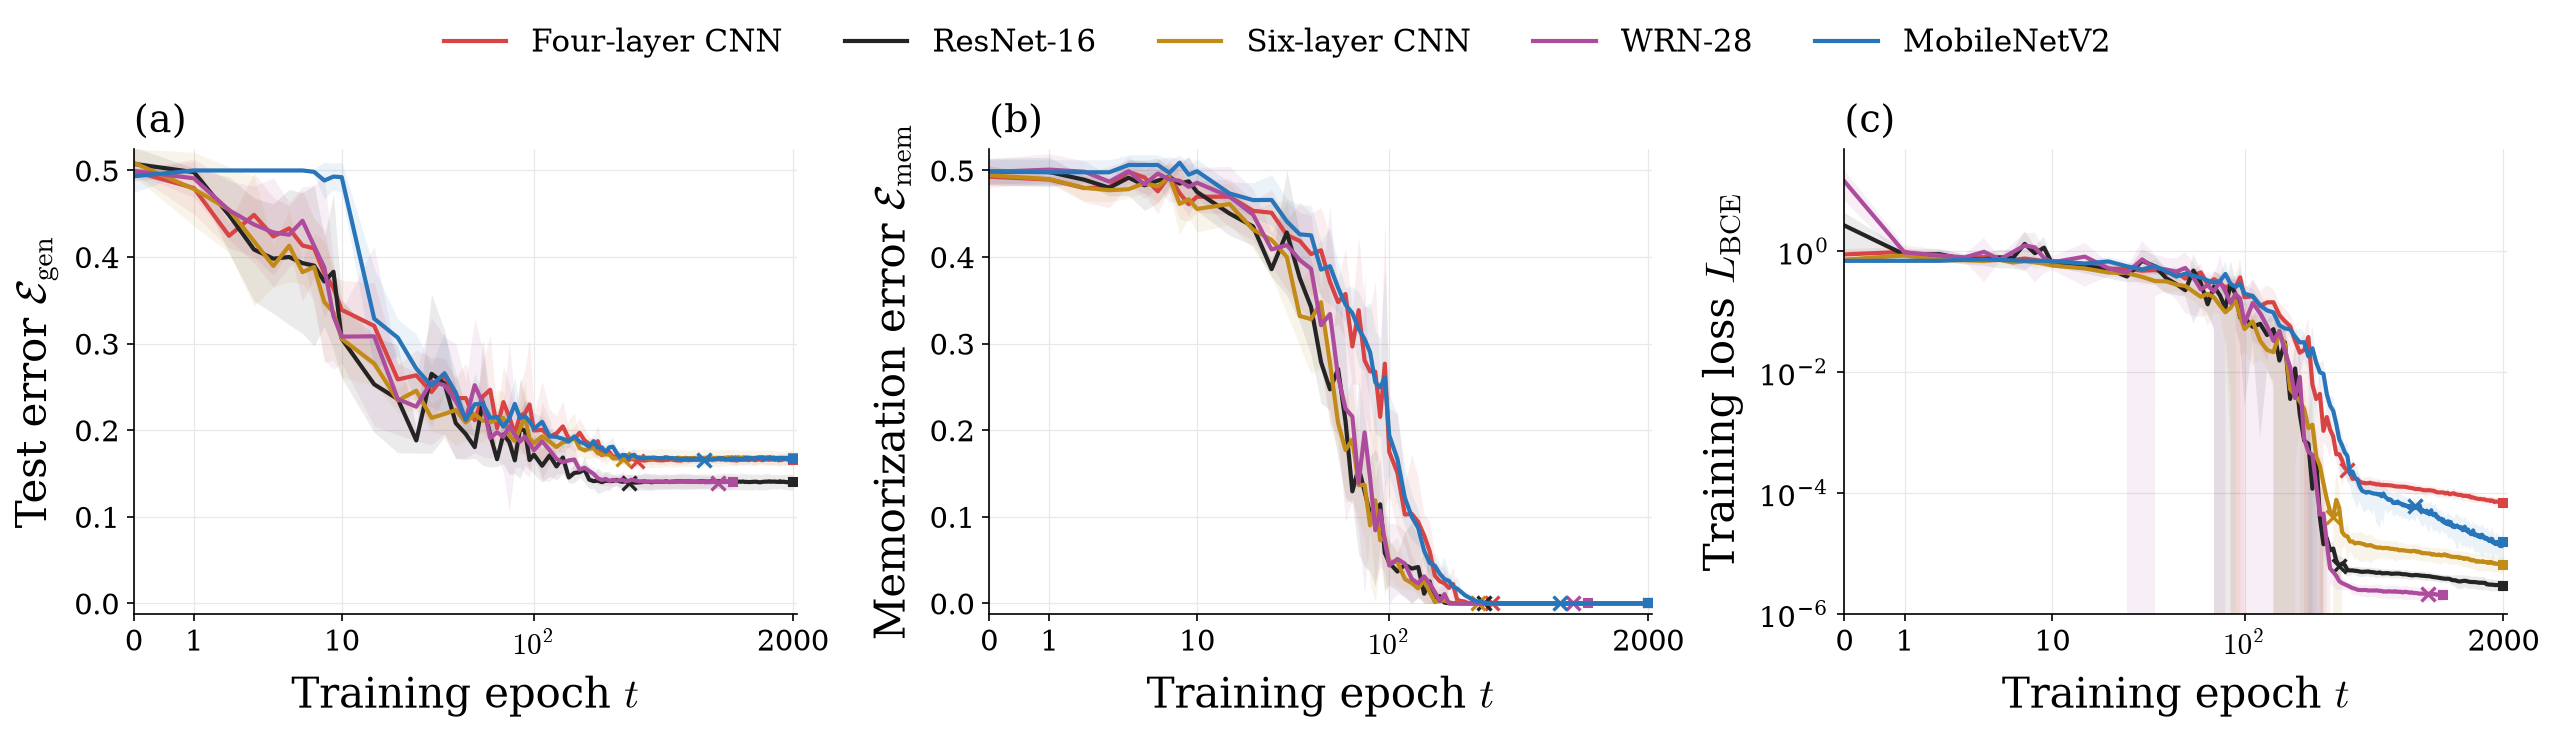

In [5]:
plt.rcdefaults()
plt.rcParams.update({"font.family":"serif", "mathtext.fontset":"cm", "font.size":15,
    "axes.labelsize":20, "xtick.labelsize":14, "ytick.labelsize":14, "pdf.fonttype":42,
    "axes.spines.top":False, "axes.spines.right":False})
d = load(10)
fig,axes = plt.subplots(1,3,figsize=(17.2,5.0))
for a,(name,color) in BCE.items():
    g = d[d.architecture==a].sort_values("time")
    x = np.log10(1+g.time.to_numpy()); best = np.argmin(g.E_gen.to_numpy())
    for col,m in enumerate(("E_gen","E_mem","train_loss")):
        ax = axes[col]; y = g[m].to_numpy()
        ax.plot(x,y,color=color,lw=2,label=name)
        ax.fill_between(x,g[m+"_lower"],g[m+"_upper"],color=color,alpha=.09,lw=0)
        ax.plot(x[best],y[best],"x",color=color,ms=7,mew=1.6)
        ax.plot(x[-1],y[-1],"s",color=color,ms=4)
for col,(ax,label) in enumerate(zip(axes,[r"Test error $\mathcal{E}_{\rm gen}$",
        r"Memorization error $\mathcal{E}_{\rm mem}$",r"Training loss $L_{\rm BCE}$"])):
    ax.set_xlabel(r"Training epoch $t$",labelpad=7); ax.set_ylabel(label,labelpad=7)
    ax.set_title(f"({chr(97+col)})",loc="left",fontsize=18,pad=8)
    ax.set_xticks(np.log10(1+np.array([0,1,10,100,2000])),["0","1","10",r"$10^2$","2000"])
    ax.set_xlim(0,np.log10(2001)+.02)
    ax.grid(True,color=".91",lw=.6); ax.set_axisbelow(True)
    if col<2:
        ax.set_ylim(-.012,.525)
    else:
        ax.set_yscale("log"); ax.set_ylim(bottom=min(1e-6,d.loc[d.train_loss>0,"train_loss"].min()/2))
fig.legend(*axes[0].get_legend_handles_labels(),loc="upper center",ncol=5,frameon=False,fontsize=15)
fig.subplots_adjust(top=.80,bottom=.18,left=.07,right=.99,wspace=.29)
save(fig,10)


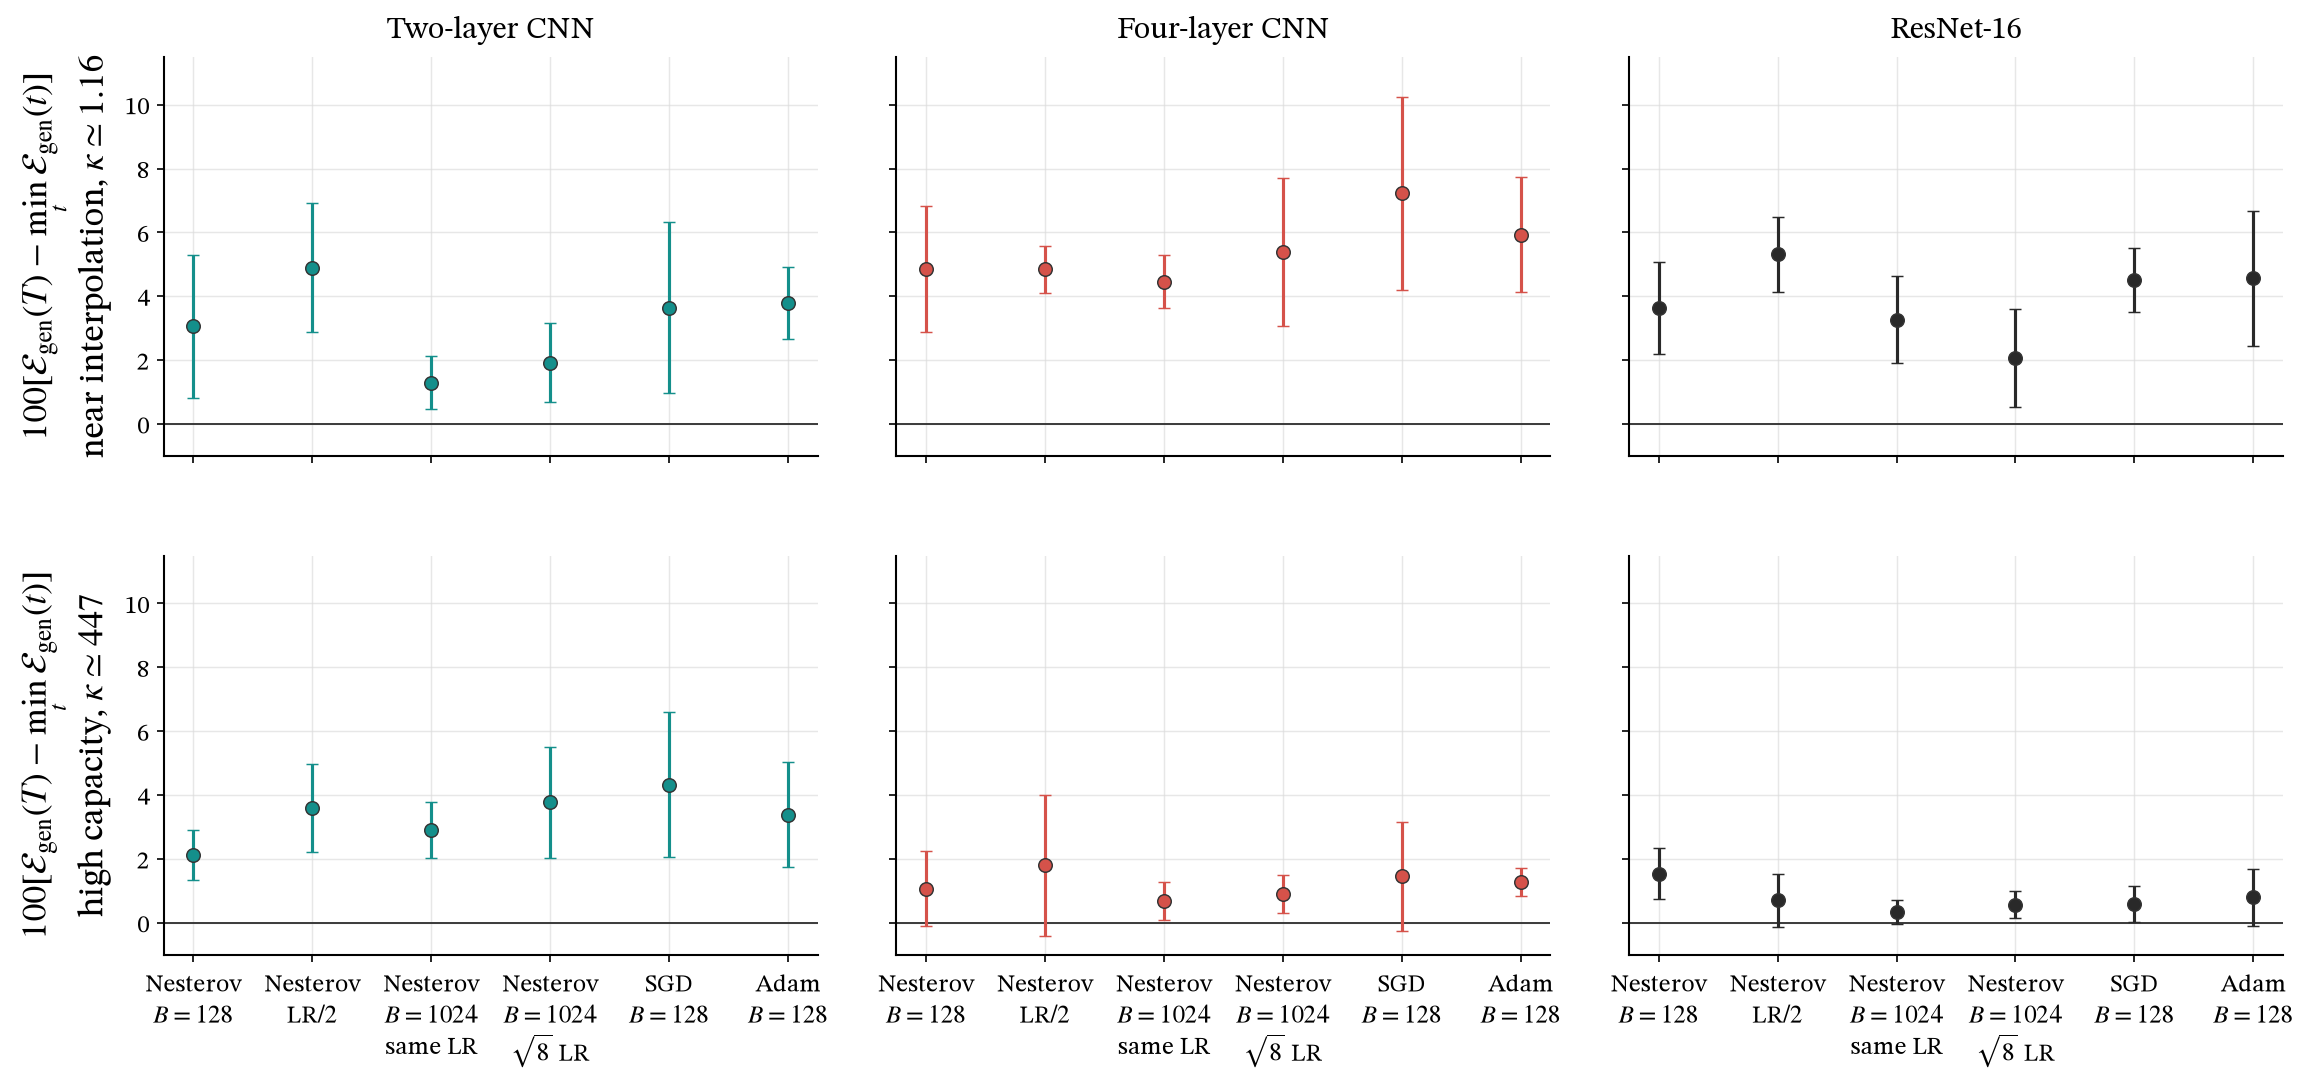

In [6]:
def style_controls():
    plt.rcdefaults()
    plt.rcParams.update({"font.family":"serif", "font.serif":SERIF_FONTS,
        "mathtext.fontset":"stix", "text.usetex":False, "font.size":13, "axes.titlesize":15,
        "axes.labelsize":17, "legend.fontsize":11.5, "xtick.labelsize":12, "ytick.labelsize":12,
        "axes.linewidth":1., "lines.linewidth":2.4, "lines.markersize":6.5, "savefig.dpi":300,
        "pdf.fonttype":42, "ps.fonttype":42})

def grid(ax):
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.grid(True,which="major",color="#dddddd",linewidth=.7,alpha=.7)

style_controls()
d = load(11)
protocols = ("nesterov_b128","nesterov_b128_half","nesterov_b1024_fixed",
             "nesterov_b1024_sqrt","sgd_b128","adam_b128")
labels = ("Nesterov\n$B=128$","Nesterov\nLR$/2$","Nesterov\n$B=1024$\nsame LR",
          "Nesterov\n$B=1024$\n"+r"$\sqrt{8}$ LR","SGD\n$B=128$","Adam\n$B=128$")
styles = {"two_layer":("Two-layer CNN","#148F8B"), "shallow":("Four-layer CNN","#D5524A"),
          "residual":("ResNet-16","#292929")}
fig,axes = plt.subplots(2,3,figsize=(15.7,8.2),sharex=True,sharey=True)
for row,tier in enumerate(("interpolation","high")):
    for col,(a,(name,color)) in enumerate(styles.items()):
        ax = axes[row,col]
        g = d[(d.tier==tier)&(d.architecture==a)].set_index("protocol").loc[list(protocols)]
        x = np.arange(len(protocols))
        ax.errorbar(x,g.gap_pp,yerr=g.ci95_halfwidth_pp,fmt="o",color=color,
            markerfacecolor=color,markeredgecolor="#333333",markeredgewidth=.7,capsize=3.,linewidth=1.5,zorder=3)
        ax.axhline(0.,color="#333333",linewidth=.9)
        ax.set_ylim(-1.,11.5); ax.set_xticks(x); ax.set_xticklabels(labels)
        grid(ax)
        if row==0: ax.set_title(name,pad=9)
        if col==0:
            tier_label = r"near interpolation, $\kappa\simeq1.16$" if tier=="interpolation" else r"high capacity, $\kappa\simeq447$"
            ax.set_ylabel(r"$100[\mathcal{E}_{\rm gen}(T)-\min_t\mathcal{E}_{\rm gen}(t)]$"+"\n"+tier_label)
fig.subplots_adjust(top=.91,bottom=.18,left=.09,right=.99,hspace=.25,wspace=.12)
save(fig,11)


In [7]:
STYLE = {
    'rf_readout': ('RF-CNN (readout matched)', '#2875B9'),
    'cnn2': ('Two-layer CNN', '#009B83'), 'cnn4': ('Four-layer CNN', '#D84343'),
    'cnn6': ('Six-layer CNN', '#C28B18'), 'res16': ('ResNet-16', '#242424'),
    'res28': ('WRN-28', '#AD4B9C'), 'mobilev2': ('MobileNetV2', '#2875B9')}

def style(square=True):
    plt.rcdefaults()
    plt.rcParams.update({'font.family':'serif', 'mathtext.fontset':'cm', 'font.size':18 if square else 16,
        'axes.labelsize':26 if square else 28, 'axes.titlesize':24, 'xtick.labelsize':18 if square else 16,
        'ytick.labelsize':18 if square else 16, 'legend.fontsize':21 if square else 16,
        'pdf.fonttype':42, 'ps.fonttype':42, 'axes.spines.top':False, 'axes.spines.right':False})

def save_path(fig, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches='tight')
    save_paper_alias(fig, int(path.stem.removeprefix('Figure')))
    fig.savefig(path.with_suffix('.png'), dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f'PDF: {path.resolve()}')

def legend(architectures):
    return [Line2D([], [], color=STYLE[a][1], lw=2.5, label=STYLE[a][0]) for a in architectures]

def path_line(ax, frame, architecture, arrows=False):
    color = STYLE[architecture][1]
    g = frame.sort_values('time')
    x, y = g.E_gen.to_numpy(), g.E_mem.to_numpy()
    ax.plot(x, y, color=color, lw=2.3, label=STYLE[architecture][0])
    ax.plot(x[0], y[0], '^', color=color, ms=6)
    ax.plot(x[-1], y[-1], 's', color=color, ms=5, zorder=4)
    i = int(np.argmin(x))
    ax.plot(x[i], y[i], 'x', color=color, ms=9, mew=2, zorder=5)
    if arrows:
        for target in (50, 150):
            i = np.searchsorted(g.time.to_numpy(), target)
            if 0 < i < len(x) and (x[i], y[i]) != (x[i-1], y[i-1]):
                ax.annotate('', xy=(x[i], y[i]), xytext=(x[i-1], y[i-1]),
                    arrowprops=dict(arrowstyle='->', color=color, lw=1.6, mutation_scale=17))

def draw_main(d, protocol, path):
    square = protocol == 'square'
    style(square)
    architectures = ('rf_readout', 'cnn2', 'cnn4', 'res28') if square else ('cnn4', 'res16', 'res28', 'mobilev2')
    fig, axes = plt.subplots(1, 3 if square else 1, figsize=(18.8, 6.7) if square else (8.8, 6.8),
                             sharex=True, sharey=True, squeeze=False)
    for i, ax in enumerate(axes[0]):
        for a in architectures:
            g = d[d.architecture == a]
            if square:
                g = g[g.kappa == (1, 10, 100)[i]]
            path_line(ax, g, a, arrows=not square)
        if square:
            ax.set_title(rf'({chr(97+i)}) $\kappa\approx {(1,10,100)[i]}$', pad=12)
        ax.set_xlim(max(0., min(.11 if not square else 1., d.E_gen.min()-.025)), max(.52, d.E_gen.max()+.025))
        ax.set_ylim(-.018, max(.515, d.E_mem.max()+.02))
        ax.set_yticks(np.arange(0, .51, .1))
        ax.grid(True, color='.9', lw=.65)
        ax.set_axisbelow(True)
        ax.set_xlabel(r'Test error $\mathcal{E}_{\rm gen}$', labelpad=10)
    axes[0, 0].set_ylabel(r'Memorization error $\mathcal{E}_{\rm mem}$', labelpad=12)
    fig.legend(handles=legend(architectures), loc='upper center', ncol=4 if square else 2, frameon=False)
    fig.subplots_adjust(top=.76 if square else .82, bottom=.17 if square else .16,
                        left=.068 if square else .16, right=.985, wspace=.12)
    save_path(fig, path)

def draw_times(d, protocol, path, test_loss=False):
    square = protocol == 'square'
    style(square)
    architectures = ('cnn2', 'cnn4', 'cnn6', 'res16', 'res28') if square else ('cnn4', 'res16', 'cnn6', 'res28', 'mobilev2')
    metrics = ['E_gen', 'E_mem', 'train_loss'] + (['test_loss'] if test_loss else [])
    labels = [r'Test error $\mathcal{E}_{\rm gen}$', r'Memorization error $\mathcal{E}_{\rm mem}$',
              r'Training loss $L_{\rm train}$' if square else r'Training loss $L_{\rm BCE}$', r'Test loss $L_{\rm test}$']
    if square:
        labels = ['Test error\n'+r'$\mathcal{E}_{\rm gen}$', 'Memorization error\n'+r'$\mathcal{E}_{\rm mem}$',
                  'Training loss\n'+r'$L_{\rm train}$', 'Test loss\n'+r'$L_{\rm test}$']
    if square:
        fig, axes = plt.subplots(len(metrics), 3, figsize=(18.8, 12.8 if not test_loss else 16), sharex=True, sharey='row')
    else:
        plt.rcParams.update({'axes.labelsize':20, 'xtick.labelsize':14, 'ytick.labelsize':14})
        fig, axes = plt.subplots(1, len(metrics), figsize=(17.2 if not test_loss else 22, 5), squeeze=False)
    horizon = int(d[d.architecture != 'rf_readout'].time.max())
    ticks = [0, 10, 100, horizon] if square else [0, 1, 10, 100, horizon]
    ticks = sorted(set(v for v in ticks if v <= horizon))
    for col in range(3 if square else 1):
        for a in architectures:
            g = d[d.architecture == a]
            if square:
                g = g[g.kappa == (1, 10, 100)[col]]
            g = g.sort_values('time')
            x = np.log10(1+g.time.to_numpy())
            best, color = np.argmin(g.E_gen.to_numpy()), STYLE[a][1]
            for row, metric in enumerate(metrics):
                ax = axes[row, col] if square else axes[0, row]
                y = g[metric].to_numpy()
                ax.plot(x, y, color=color, lw=2.2)
                lower, upper = g[metric+'_lower'].to_numpy(), g[metric+'_upper'].to_numpy()
                if metric == 'train_loss':
                    lower = np.where(lower > 0, lower, np.nan)
                ax.fill_between(x, lower, upper, color=color, alpha=.12 if square else .09, linewidth=0)
                ax.plot(x[-1], y[-1], 's', color=color, ms=4)
                ax.plot(x[best], y[best], 'x', color=color, ms=7, mew=1.6)
        for row, metric in enumerate(metrics):
            ax = axes[row, col] if square else axes[0, row]
            ax.grid(True, color='.9', lw=.65)
            ax.set_axisbelow(True)
            ax.set_xlim(0, np.log10(1+horizon)*1.025)
            ticklabels = [r'$10^1$' if square and v == 10 else r'$10^2$' if v == 100 else f'{v:,}' for v in ticks]
            ax.set_xticks(np.log10(1+np.array(ticks)), ticklabels)
            if metric == 'train_loss':
                ax.set_yscale('log', nonpositive='mask')
            elif metric == 'E_mem':
                ax.set_ylim(bottom=-.018)
                ax.set_yticks(np.arange(0, .51, .2 if square else .1))
            if not square and metric.startswith('E_'):
                ax.set_ylim(-.012, .525)
            if not square or row == len(metrics)-1:
                ax.set_xlabel(r'Training epoch $t$', labelpad=10)
            if not square or col == 0:
                ax.set_ylabel(labels[row], labelpad=10, fontsize=22 if square else 20)
            if not square:
                ax.set_title(f'({chr(97+row)})', loc='left', fontsize=18)
        if square:
            axes[0, col].set_title(rf'({chr(97+col)}) $\kappa\approx {(1,10,100)[col]}$', pad=10)
    fig.legend(handles=legend(architectures), loc='upper center', ncol=3 if square else 5, frameon=False,
               fontsize=21 if square else 15)
    fig.subplots_adjust(top=.84 if square else .80, bottom=.115 if square else .18,
                        left=.07, right=.985, wspace=.12 if square else .29, hspace=.18)
    save_path(fig, path)

def draw_controls(raw, path, *, uncertainty=None, log_test=False, uncertainty_label=None, mean_summary=None, log_time=False, uncertainty_style='bars'):
    if mean_summary is None:
        raise ValueError('Supply the plotted seed summary')
    else:
        d = mean_summary[['condition_key', 'epoch', 'E_gen', 'E_mem']].copy()
    if d.duplicated(['condition_key', 'epoch']).any():
        raise RuntimeError('Duplicate control means')
    if uncertainty_style not in ('bars', 'band'):
        raise ValueError('Choose bars or band')
    if uncertainty is not None:
        d = d.merge(uncertainty[['condition_key', 'epoch', 'E_gen_half', 'E_mem_half']], on=['condition_key', 'epoch'], how='left', validate='one_to_one')
        if not np.isfinite(d.E_gen_half).all() or not np.isfinite(d.loc[d.condition_key != 'eps0', 'E_mem_half']).all():
            raise RuntimeError('Missing control uncertainty estimates')
    plt.rcdefaults()
    plt.rcParams.update({'font.family': 'serif', 'font.serif': SERIF_FONTS, 'mathtext.fontset': 'stix', 'font.size': 13, 'axes.titlesize': 15, 'axes.labelsize': 17, 'legend.fontsize': 11.5, 'xtick.labelsize': 12, 'ytick.labelsize': 12, 'axes.linewidth': 1.0, 'lines.linewidth': 2.4, 'pdf.fonttype': 42})
    panels = [('Training size ($\\epsilon=0.2$, $B=128$)', ['n_alpha0p5', 'n_alpha1', 'baseline', 'n_alpha3'], ['$n=1536$', '$n=3072$', '$n=6144$', '$n=9216$'], ['#3B0F70', '#31688E', '#35B779', '#B8DE29']), ('Batch size ($n=6144$, $\\epsilon=0.2$)', ['baseline', 'batch512_fixed', 'batch1024_fixed', 'batch512_linear', 'batch1024_linear'], ['$B=128$', '$B=512$, fixed LR', '$B=1024$, fixed LR', '$B=512$, linear LR', '$B=1024$, linear LR'], ['#252525', '#6A3D9A', '#9C6ADE', '#00897B', '#4DB6AC']), ('Factual fraction ($n=6144$, $B=128$)', ['eps0', 'eps0p1', 'baseline', 'eps0p4', 'eps0p6', 'eps0p8'], [f'$\\epsilon={v}$' for v in ('0', '0.1', '0.2', '0.4', '0.6', '0.8')], ['#0072B2', '#009E73', '#3B0F70', '#9C179E', '#E16462', '#F7B718'])]
    fig, axes = plt.subplots(2, 3, figsize=(15.7, 7.6), sharex='col', sharey='row')
    for col, (title, keys, labels, colors) in enumerate(panels):
        for key, label, color in zip(keys, labels, colors):
            g = d[d.condition_key == key].sort_values('epoch')
            if g.empty:
                raise RuntimeError(f'Missing control condition: {key}')
            axes[0, col].plot(g.epoch, g.E_gen, color=color, label=label)
            if key != 'eps0':
                axes[1, col].plot(g.epoch, g.E_mem, color=color, label=label)
            if uncertainty is not None:
                bars = g if uncertainty_style == 'band' else g[g.epoch % 50 == 0]
                for row, metric in enumerate(('E_gen', 'E_mem')):
                    if key == 'eps0' and metric == 'E_mem':
                        continue
                    y, half = (bars[metric].to_numpy(), bars[metric + '_half'].to_numpy())
                    lower, upper = (np.maximum(0.0, y - half), np.minimum(1.0, y + half))
                    if row == 0 and log_test and (lower <= 0).any():
                        raise RuntimeError('A test-error uncertainty interval reaches zero; use the linear-axis version')
                    if uncertainty_style == 'band':
                        axes[row, col].fill_between(bars.epoch, lower, upper, color=color, alpha=0.13, linewidth=0)
                    else:
                        axes[row, col].errorbar(bars.epoch, y, yerr=[y - lower, upper - y], fmt='none', ecolor=color, elinewidth=0.9, capsize=2, alpha=0.65)
        axes[0, col].set_title(title, pad=8)
        axes[0, col].legend(frameon=False, fontsize=10.3, ncol=2 if col == 2 else 1, loc='upper right' if col == 2 else 'best')
        axes[1, col].set_xlabel('training epoch $t$')
    axes[0, 0].set_ylabel('$\\mathcal{E}_{\\rm gen}(t)$')
    axes[1, 0].set_ylabel('$\\mathcal{E}_{\\rm mem}(t)$')
    axes[0, 0].set_ylim(min(0.1, d.E_gen.min() - 0.01), 0.515)
    axes[1, 0].set_ylim(-0.015, 0.515)
    axes[1, 0].set_yticks(np.arange(0, 0.6, 0.1))
    if uncertainty is not None:
        axes[0, 0].set_ylim(min(0.1, (d.E_gen - d.E_gen_half).min() * 0.95), max(0.515, (d.E_gen + d.E_gen_half).max() * 1.02))
        axes[1, 0].set_ylim(-0.015, max(0.515, (d.E_mem + d.E_mem_half).max() * 1.02))
    if log_test:
        axes[0, 0].set_yscale('log')
        from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullFormatter
        axes[0, 0].yaxis.set_major_locator(FixedLocator([0.1, 0.2, 0.3, 0.4, 0.5]))
        axes[0, 0].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        axes[0, 0].yaxis.set_minor_formatter(NullFormatter())
    for ax in axes.flat:
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(True, color='#dddddd', linewidth=0.7, alpha=0.7)
        if log_time:
            log_epoch_axis(ax, float(d.epoch.max()))
    if uncertainty_label:
        fig.suptitle(uncertainty_label, fontsize=13, y=0.99)
    fig.subplots_adjust(top=0.87 if uncertainty_label else 0.91, bottom=0.1, left=0.07, right=0.995, hspace=0.12, wspace=0.1)
    path.parent.mkdir(parents=True, exist_ok=True)
    save_path(fig, path)

def log_epoch_axis(ax, horizon):
    ax.set_xscale('function', functions=(lambda x: np.log10(1+x),
                                       lambda x: np.expm1(x*np.log(10))))
    ticks = [0] + [10**i for i in range(int(np.log10(max(1, horizon)))+1)]
    if horizon > ticks[-1]*1.5:
        ticks.append(horizon)
    ax.set_xlim(0, horizon)
    ax.set_xticks(ticks, [f'{v:g}' for v in ticks])
    ax.minorticks_off()


PDF: /Users/fabrizio/Desktop/early-stopping-minimal/Figures/Figure12.pdf


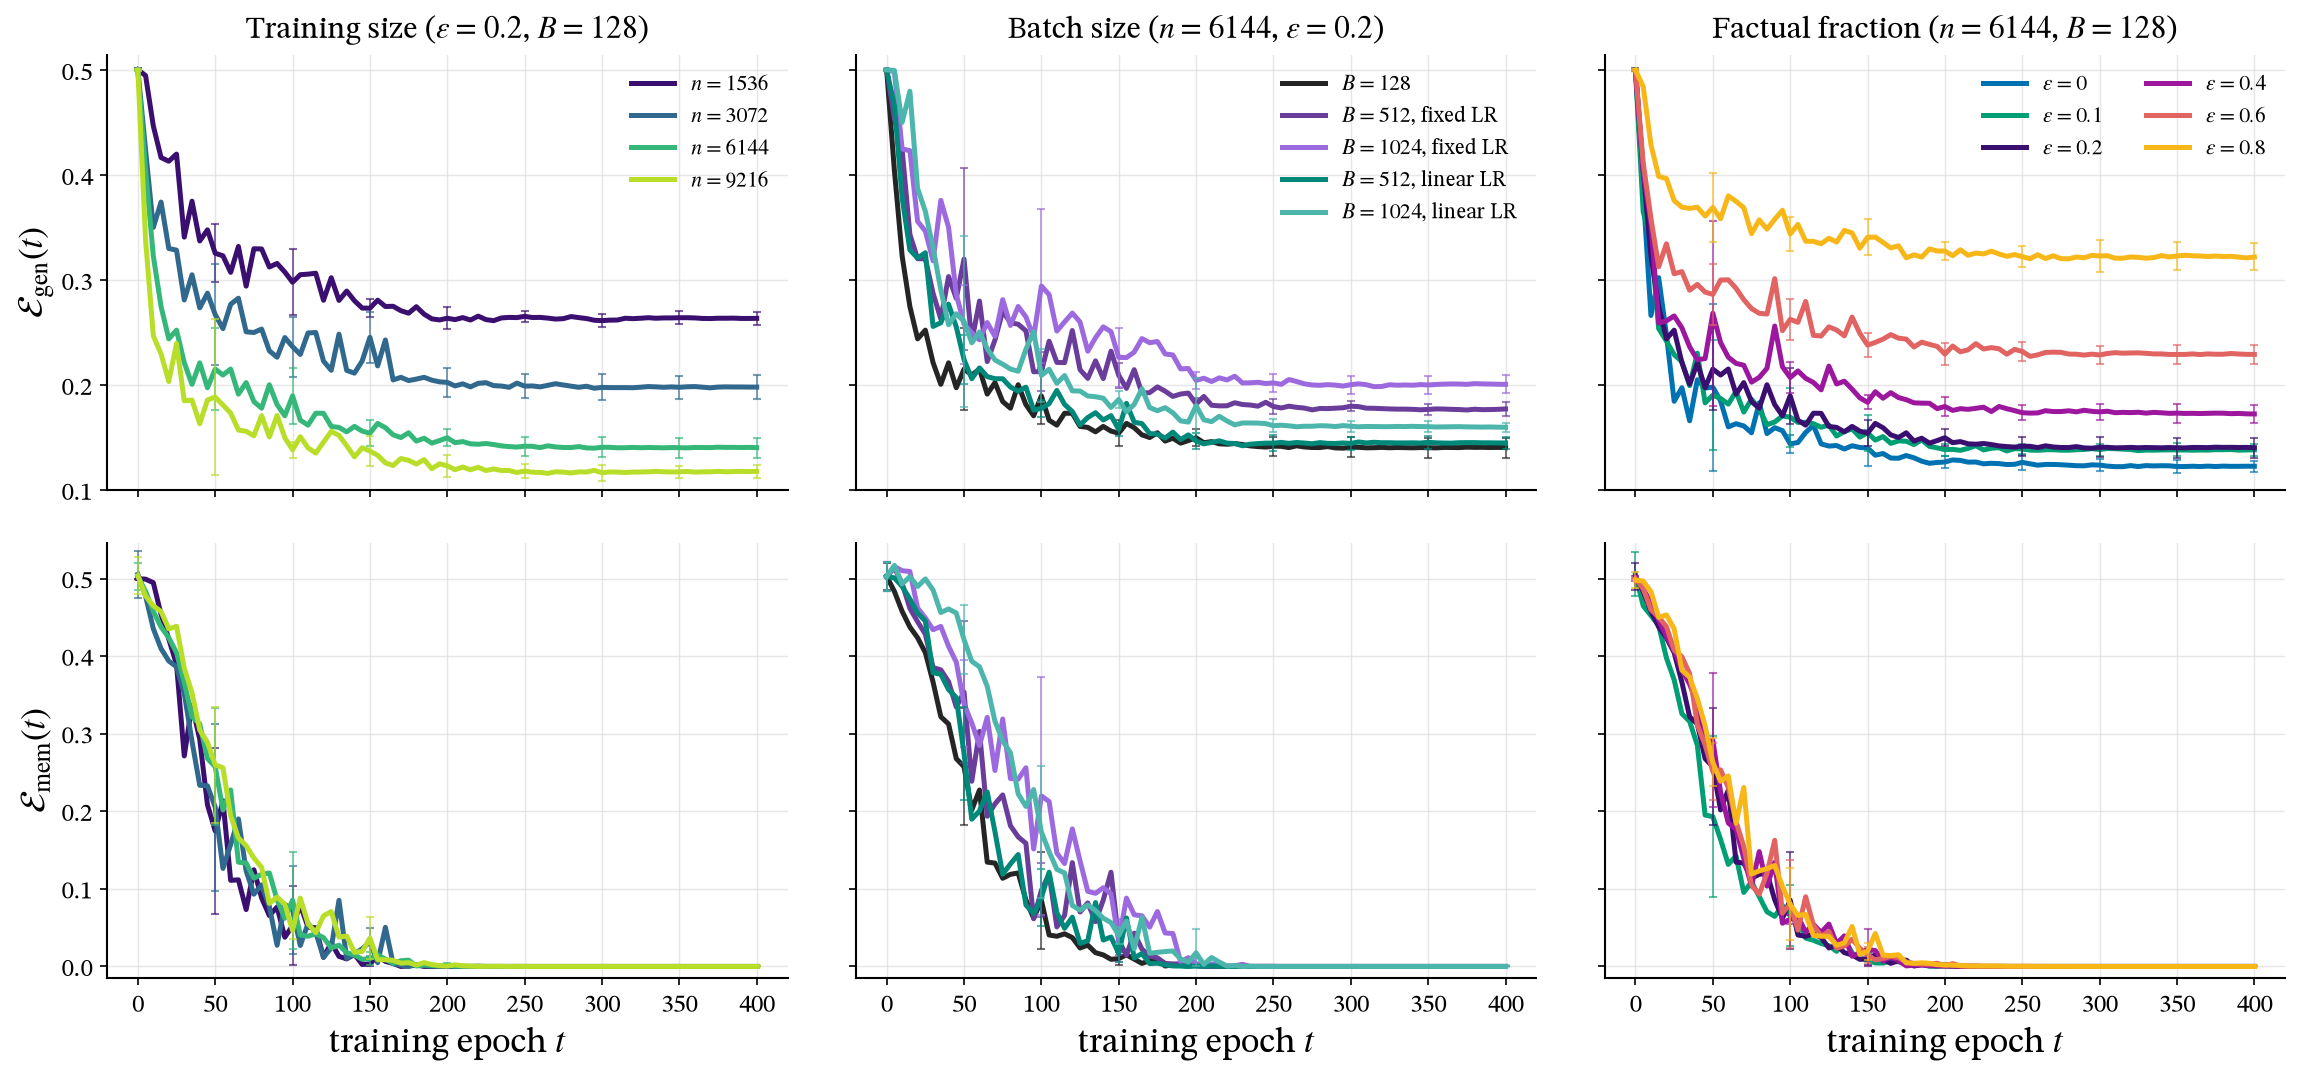

In [8]:
d = load(12)
path = OUT / 'Figure12.pdf'
draw_controls(None, path, mean_summary=d, uncertainty=d.rename(columns={'E_gen_std':'E_gen_half', 'E_mem_std':'E_mem_half'}))
display(Image(filename=str(path.with_suffix('.png')), width=1200))


PDF: /Users/fabrizio/Desktop/early-stopping-minimal/Figures/Figure13.pdf


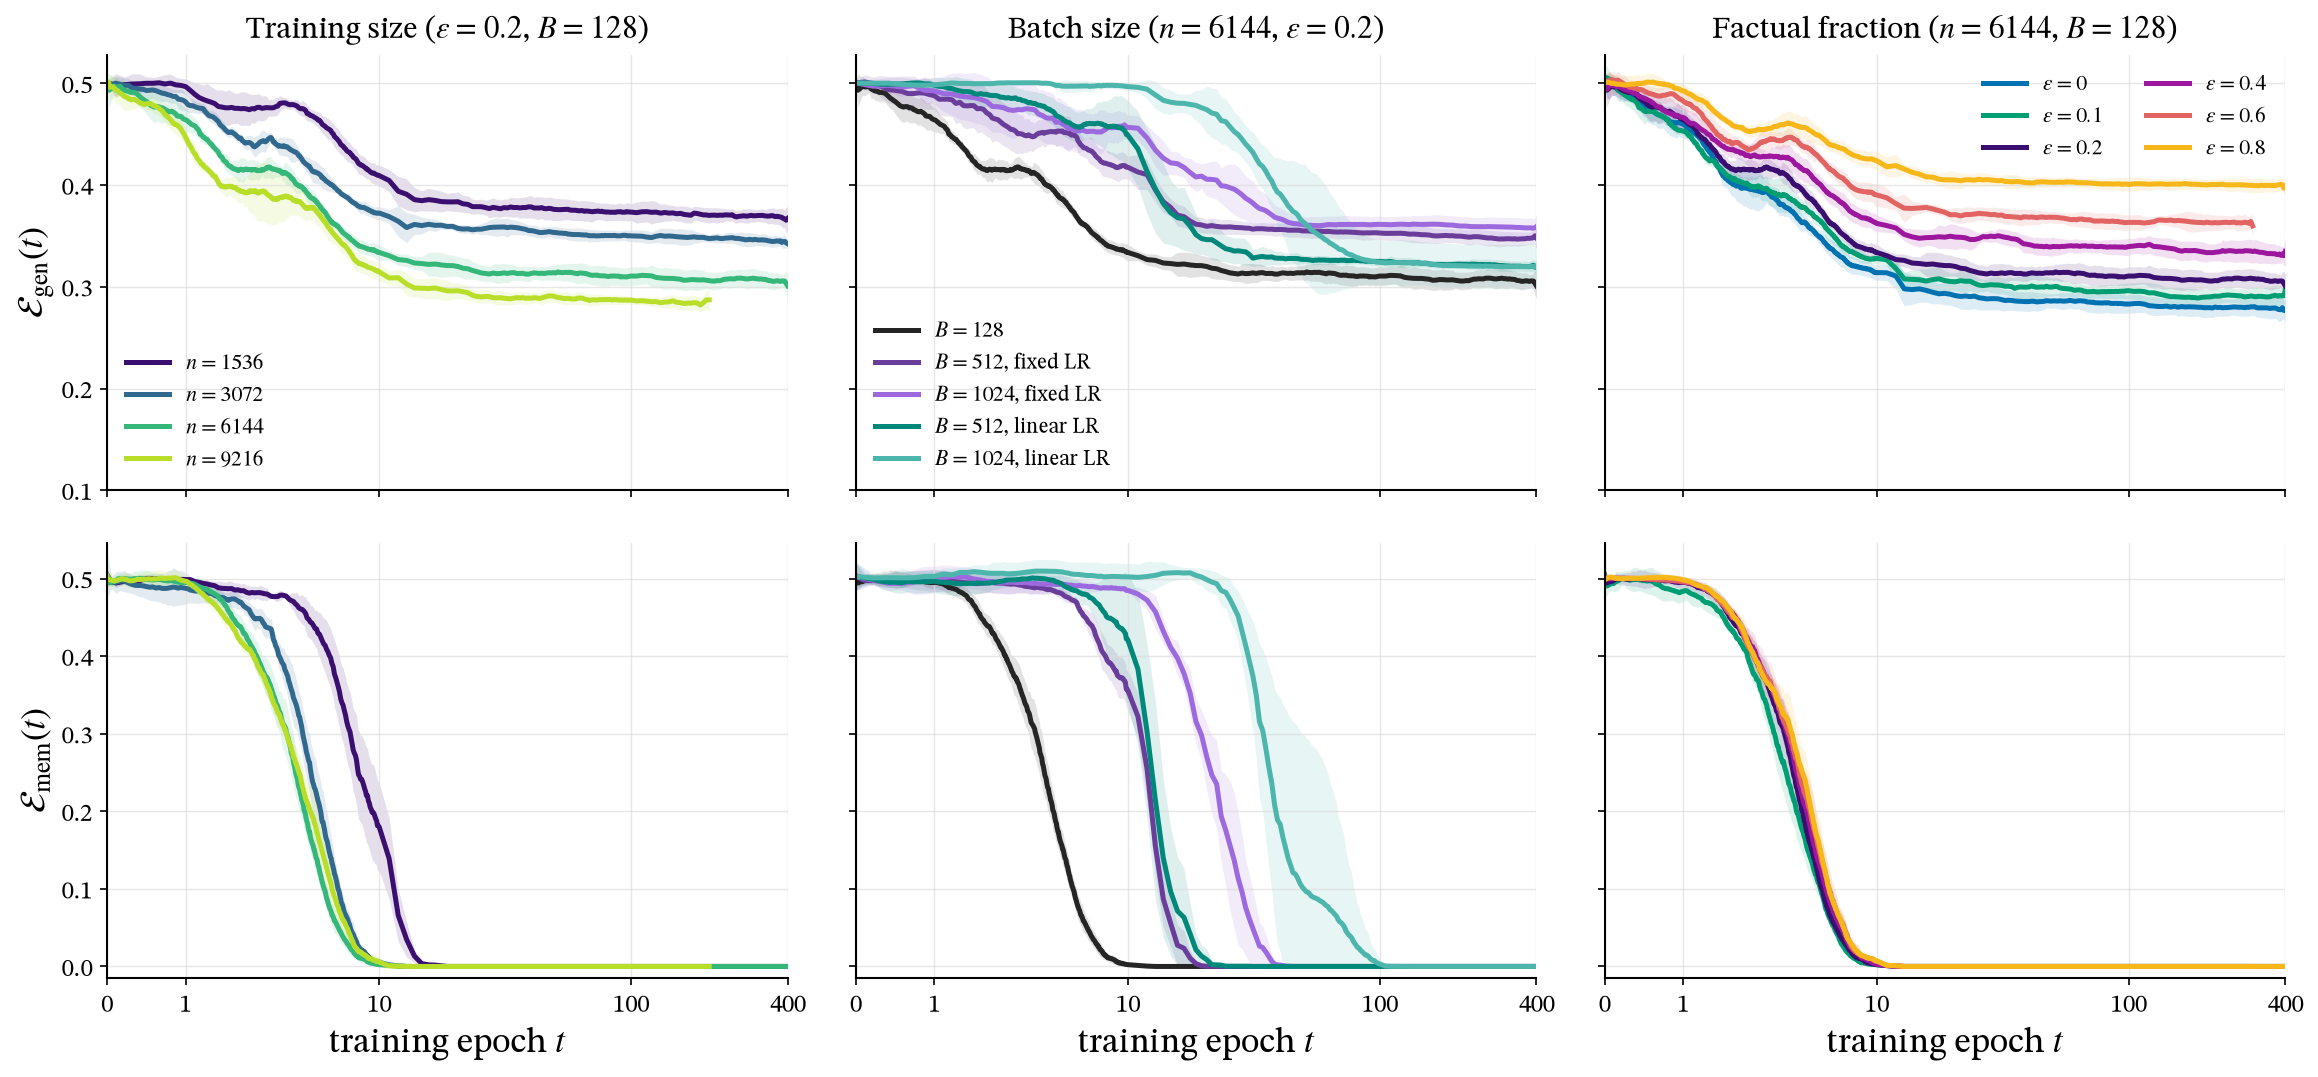

In [9]:
d = load(13)
path = OUT / 'Figure13.pdf'
draw_controls(None, path, mean_summary=d, uncertainty=d.rename(columns={'E_gen_std':'E_gen_half', 'E_mem_std':'E_mem_half'}), log_time=True, uncertainty_style='band')
display(Image(filename=str(path.with_suffix('.png')), width=1200))


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


PDF: /Users/fabrizio/Desktop/early-stopping-minimal/Figures/Figure14.pdf


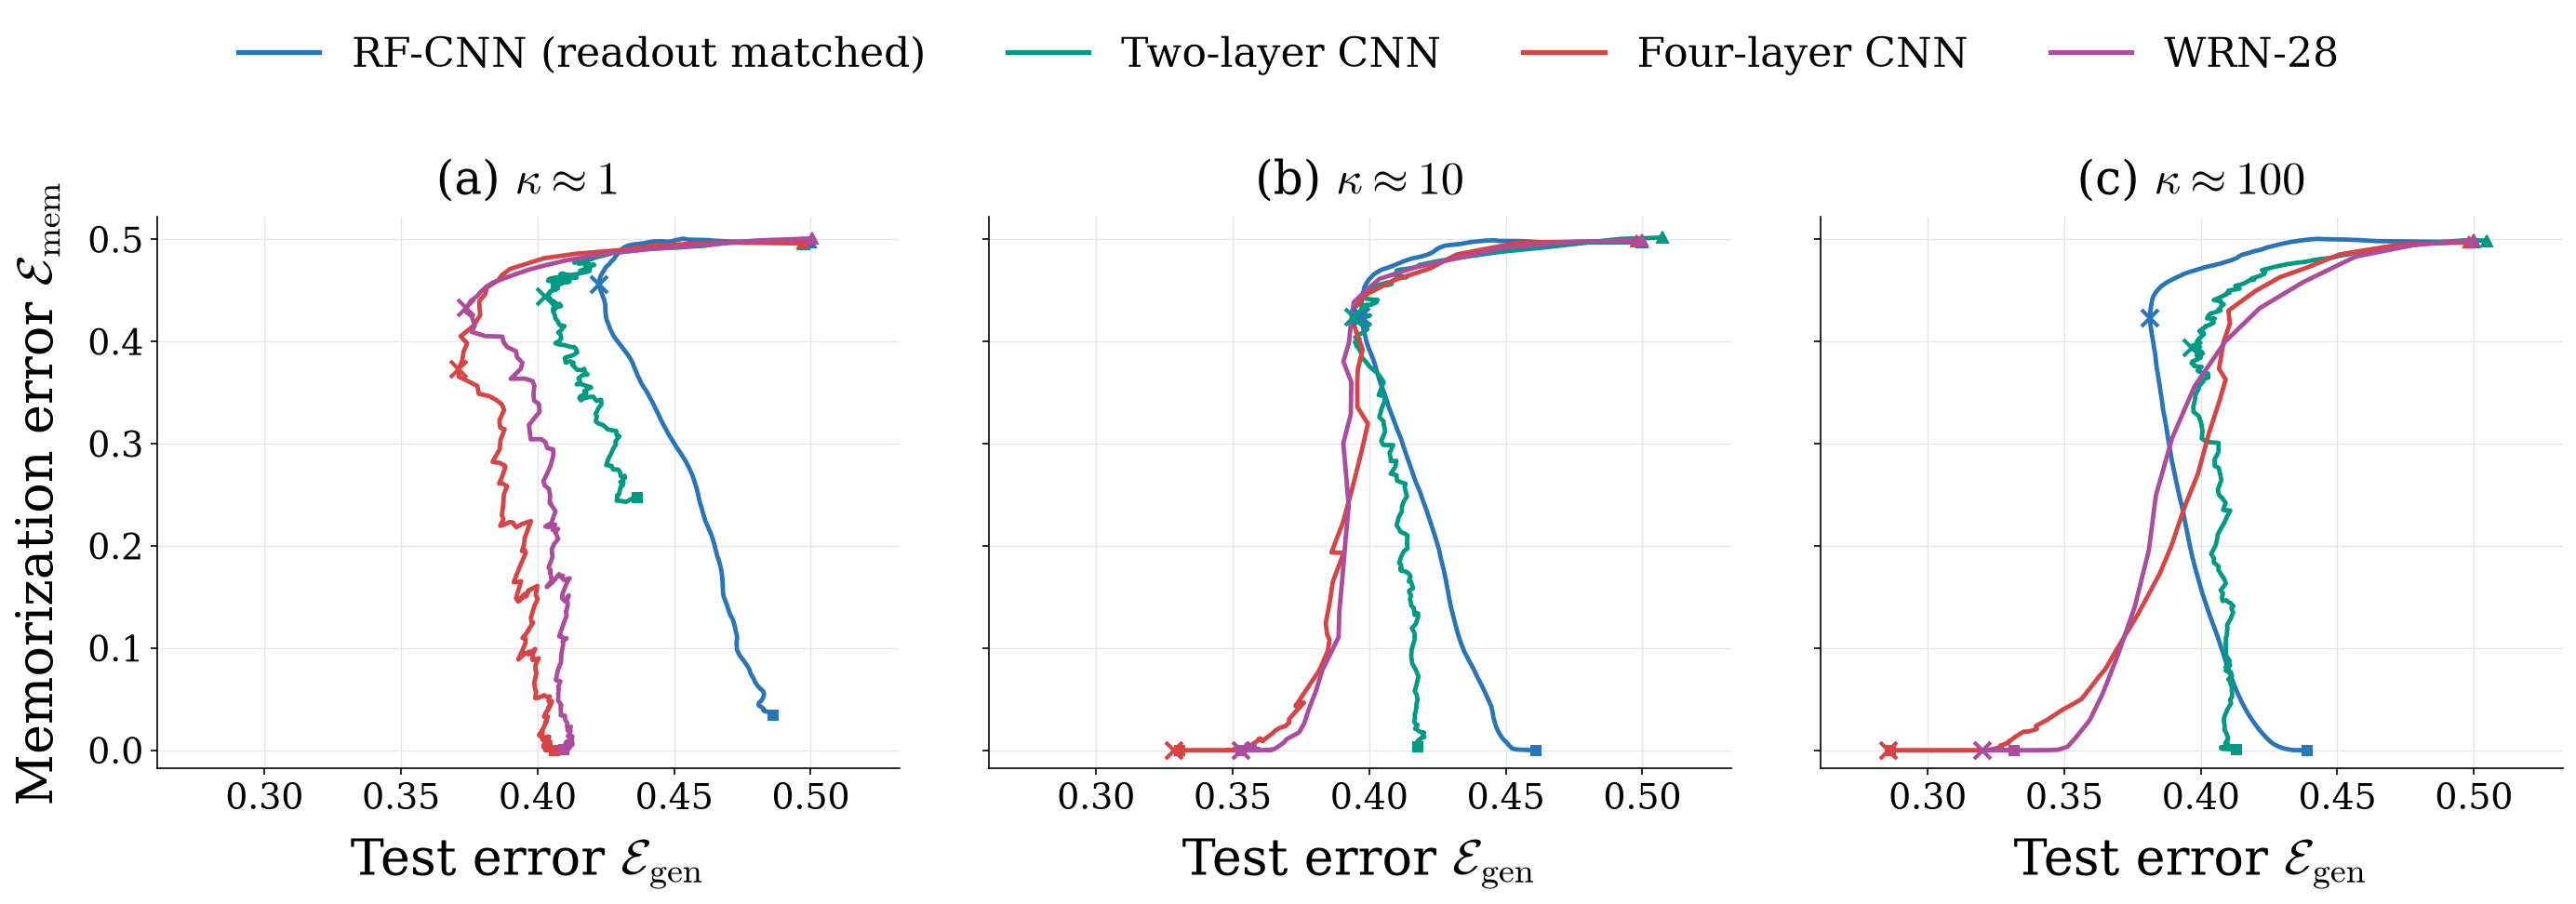

In [10]:
d = load(14)
path = OUT / 'Figure14.pdf'
draw_main(d, 'square', path)
display(Image(filename=str(path.with_suffix('.png')), width=1200))


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


PDF: /Users/fabrizio/Desktop/early-stopping-minimal/Figures/Figure15.pdf


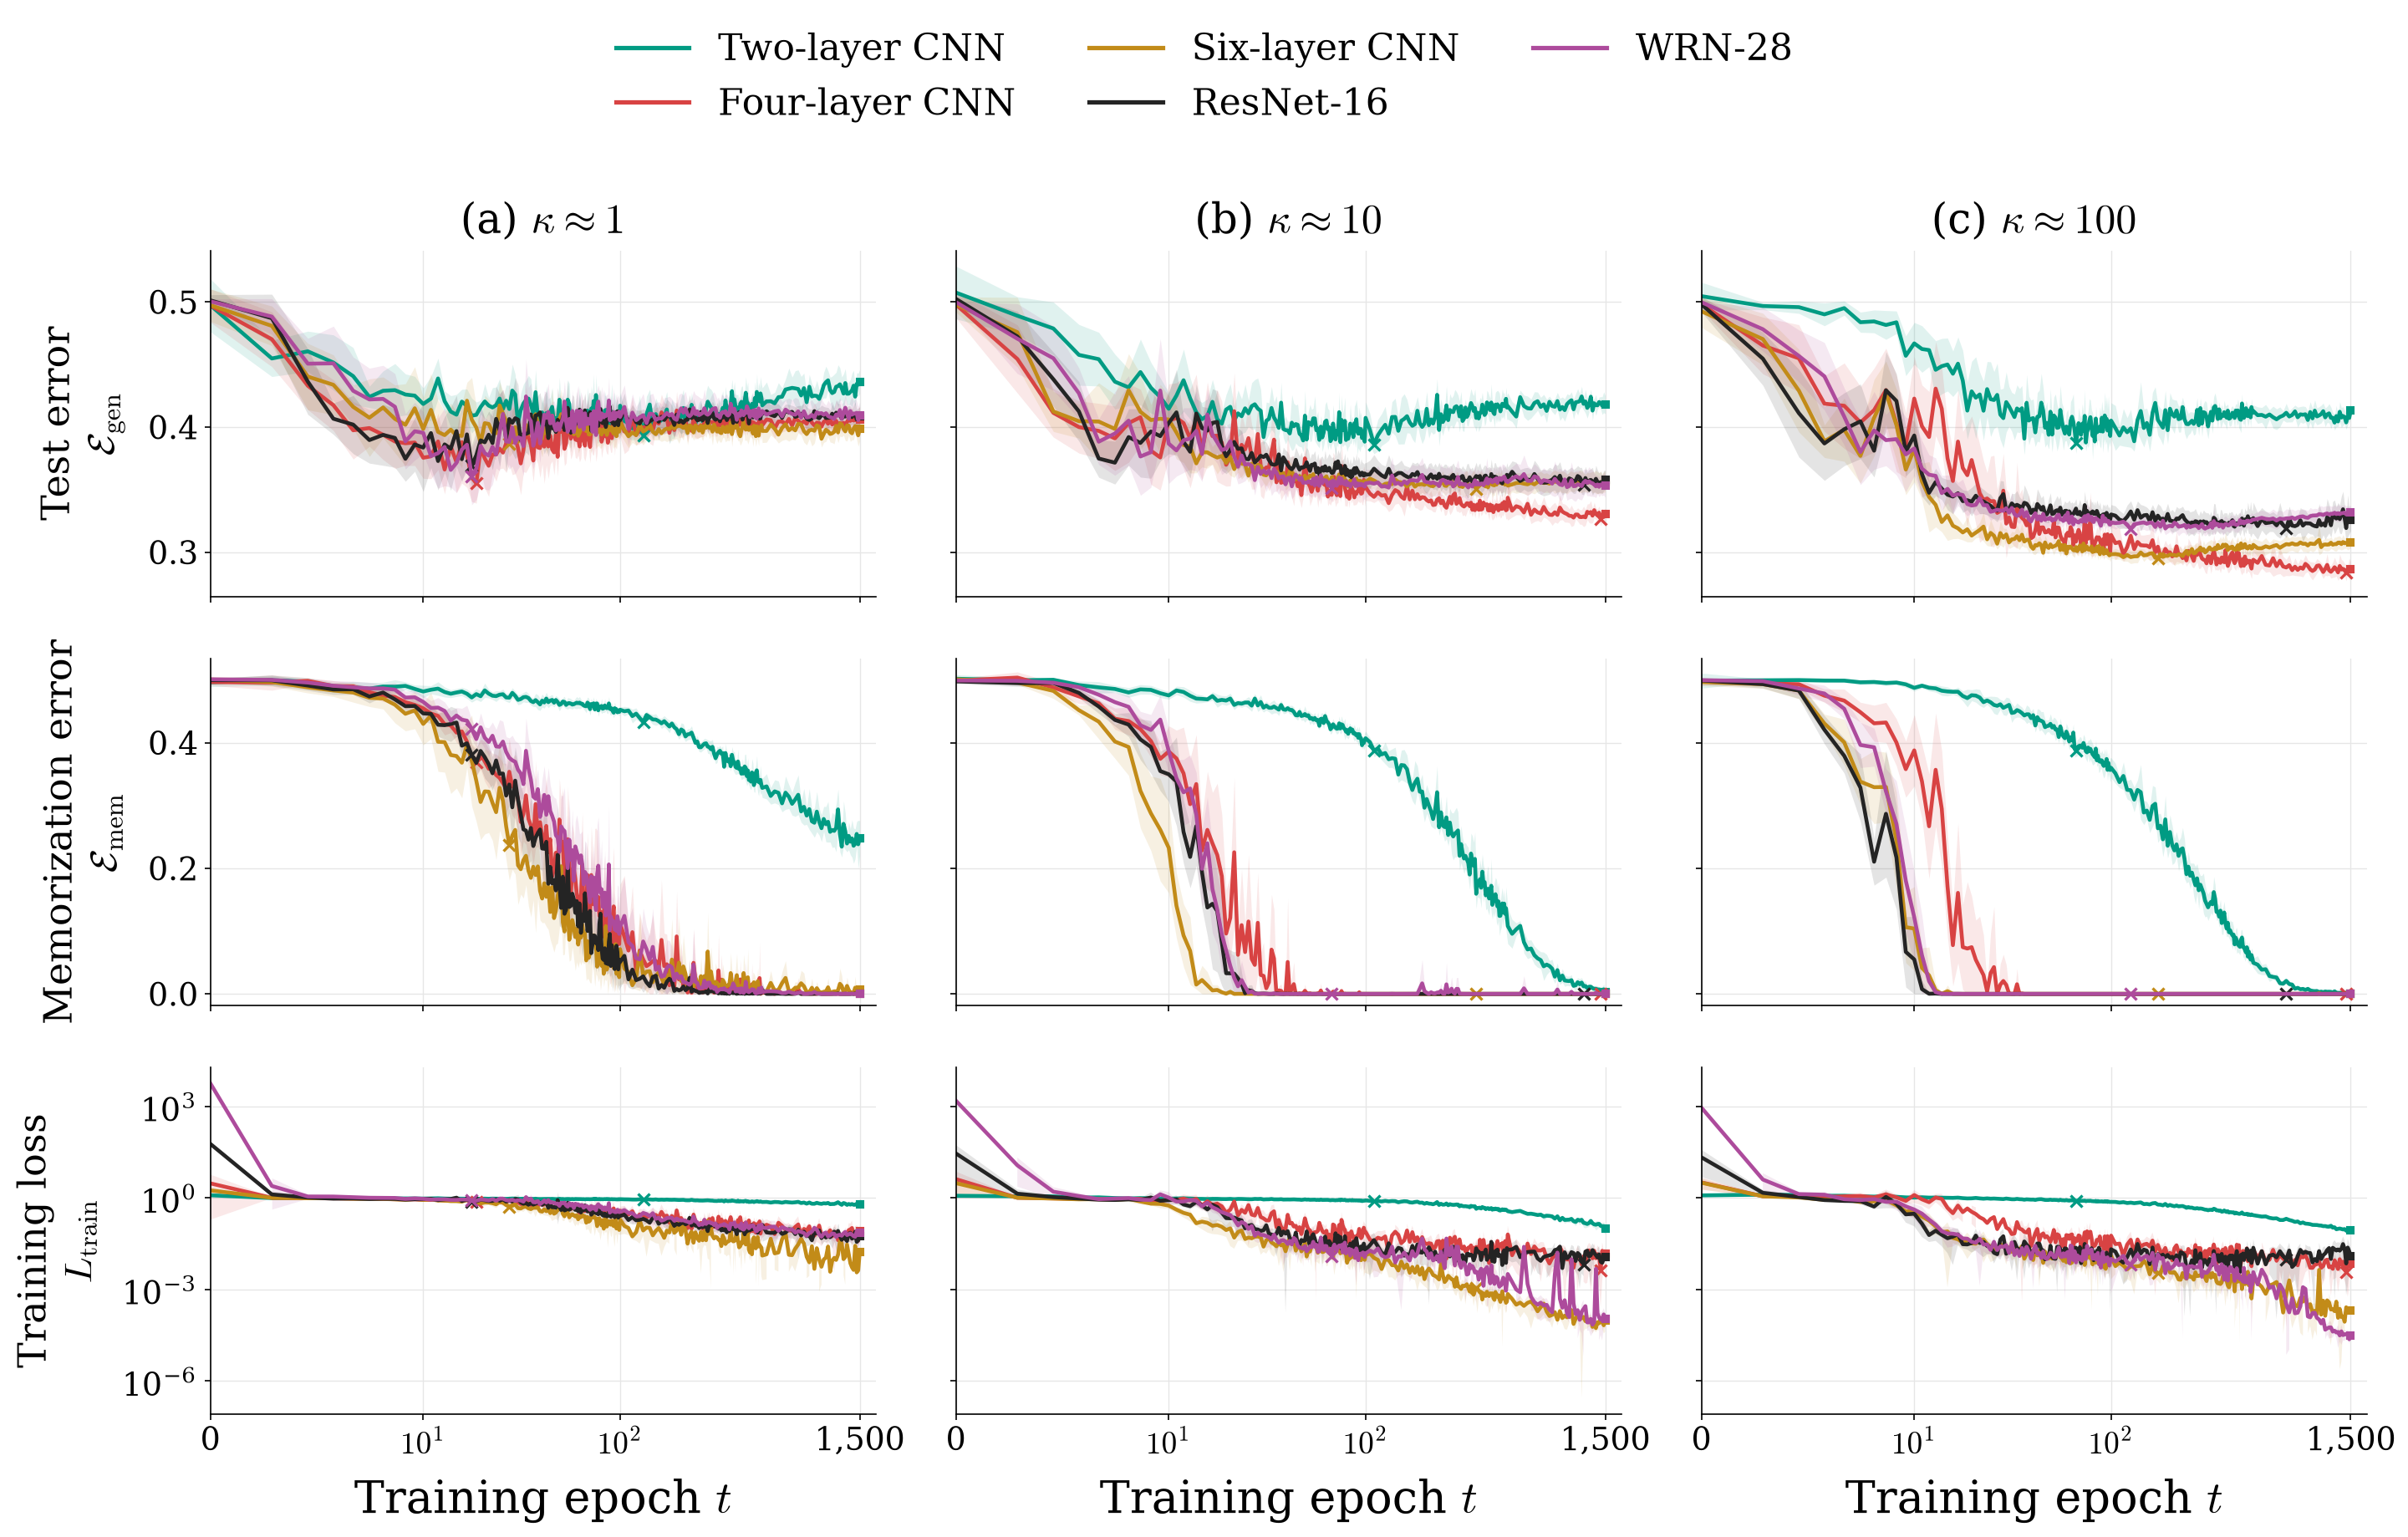

In [11]:
d = load(15)
path = OUT / 'Figure15.pdf'
draw_times(d, 'square', path)
display(Image(filename=str(path.with_suffix('.png')), width=1200))


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


PDF: /Users/fabrizio/Desktop/early-stopping-minimal/Figures/Figure16.pdf


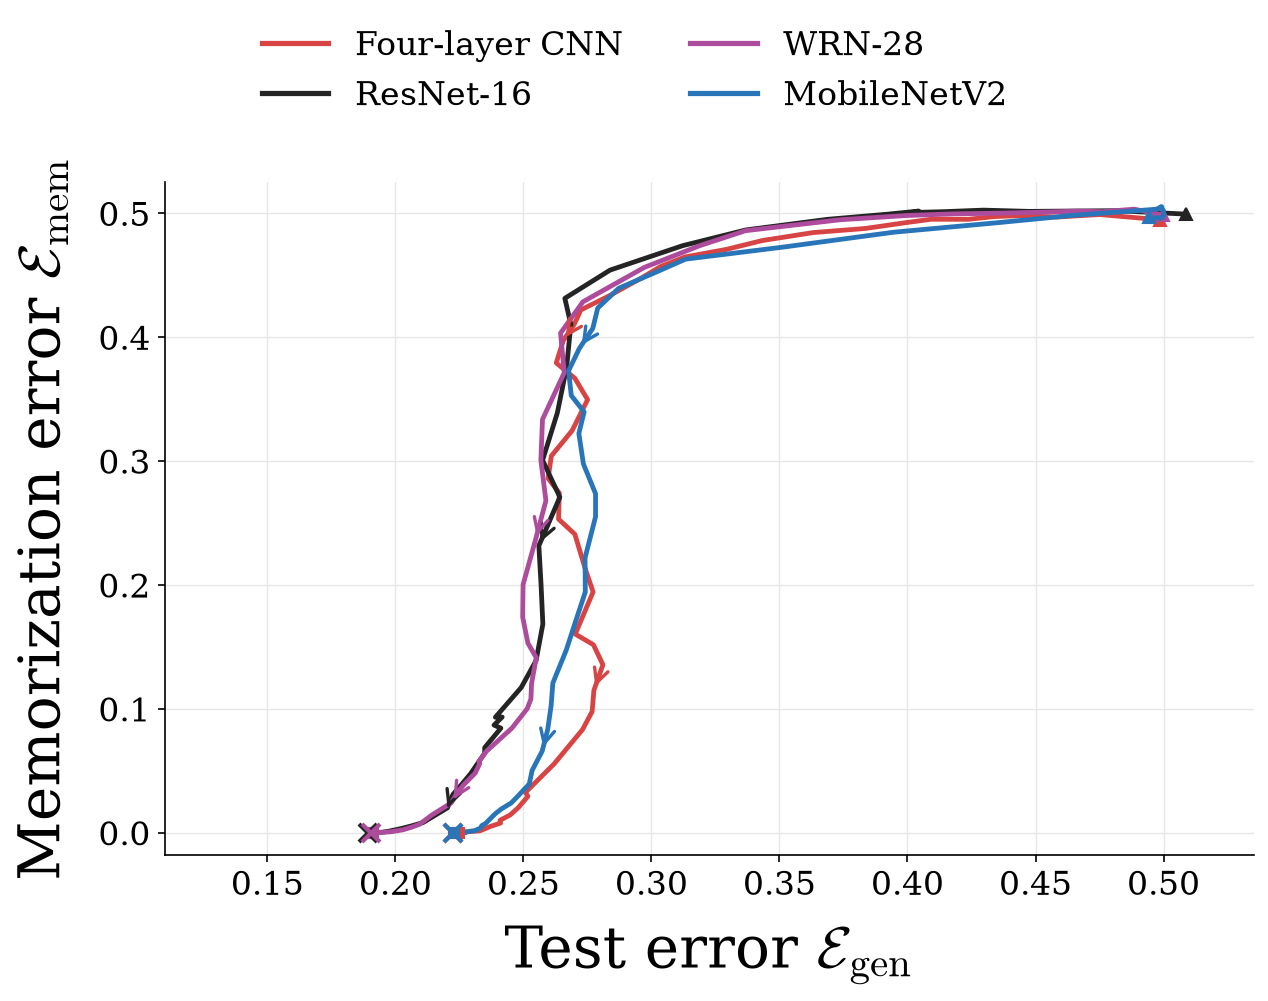

In [12]:
d = load(16)
path = OUT / 'Figure16.pdf'
draw_main(d, 'bce', path)
display(Image(filename=str(path.with_suffix('.png')), width=1200))


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


PDF: /Users/fabrizio/Desktop/early-stopping-minimal/Figures/Figure17.pdf


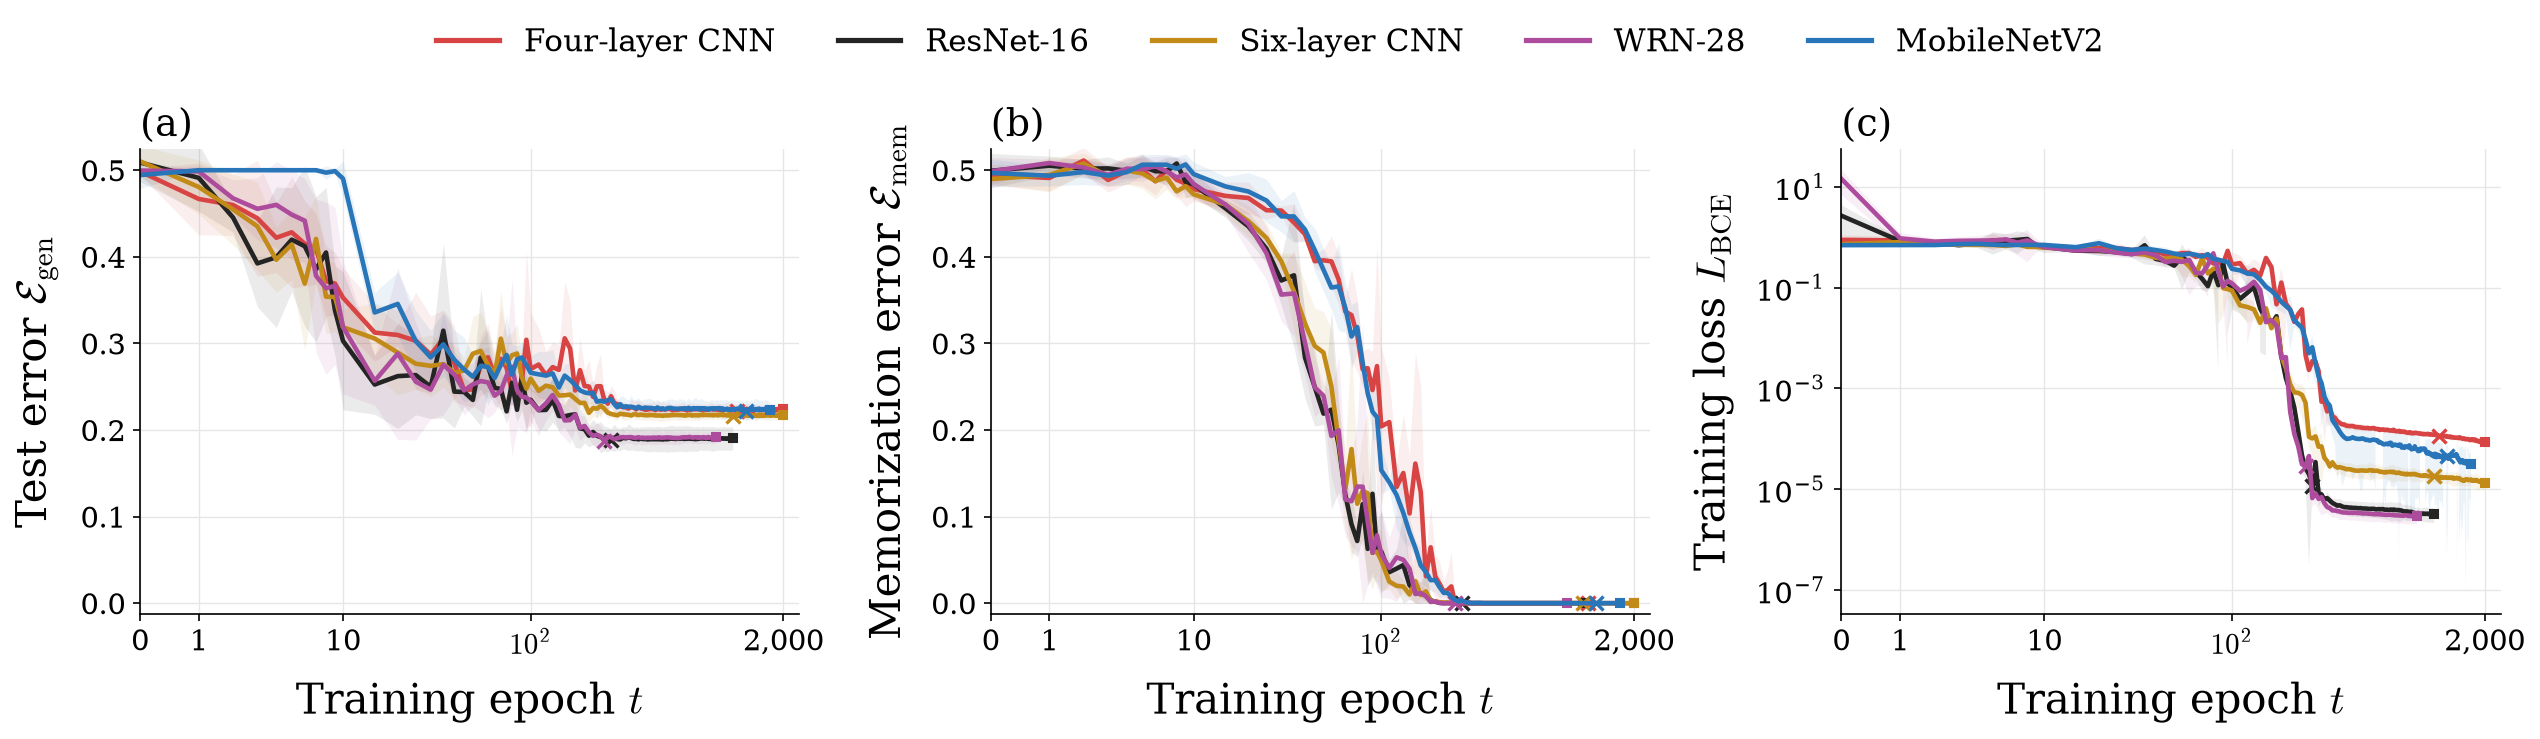

In [13]:
d = load(17)
path = OUT / 'Figure17.pdf'
draw_times(d, 'bce', path)
display(Image(filename=str(path.with_suffix('.png')), width=1200))
